In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import tifffile as tiff
import numpy as np

root_dir = Path.cwd().parents[2]
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))


from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_correlation import diagnose_resonant_scan, frame_difference_noise, spatial_noise_correlation
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.plots import plot_resonant_diagnostics, plot_motion_scale_diagnostic, plot_correlation_heatmaps
from utils.display_videos import display_videos

fig_path = root_dir.parent / "figures" / "resonancescanningfixes"


In [2]:
session_path = Path(
    "/home/wollex/Data/ScienceData/turnover_analysis/AlzheimerMice_Hayashi/845ad/Session01"
)
paths = list(session_path.glob("*.tif"))
file_path = paths[0]

In [ ]:
img_m845ad = tiff.imread(file_path).astype("float32")

In [ ]:
img_short = img_m845ad[:1000, ...]

# Calculate diagnostics

In [4]:
results_m845ad = diagnose_resonant_scan(img_m845ad)

In [5]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    fit_joint_resonant_covariance,
)

joint_fit = fit_joint_resonant_covariance(
    results_m845ad["corr_even"],
    results_m845ad["corr_odd"],
)

In [113]:
from tifffile import TiffFile, memmap
from tqdm.auto import tqdm


def save_data_as_tif(out_path, data, normalize=True):

    dims = data.shape
    T = dims[0]
    dtype = data.dtype

    normalize = True
    normalize = normalize and (not str(dtype).startswith("float"))
    max_val = np.iinfo(dtype).max if normalize else None

    def get_frame(t, normalize_by=None):
        return data[t, ...] / normalize_by if normalize_by else data[t, ...]

    memmap_image = memmap(out_path, shape=dims, dtype=dtype)

    for t in tqdm(range(T)):
        memmap_image[t, ...] = get_frame(t, normalize_by=max_val if normalize else None)

        # commit changes to file every so often to avoid memory overuse
        if not ((t + 1) % 2000) or (t + 1) == T:
            memmap_image.flush()

    del memmap_image

# Correction by downsampling to assumed native pixel size

In [70]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_downsampling import *

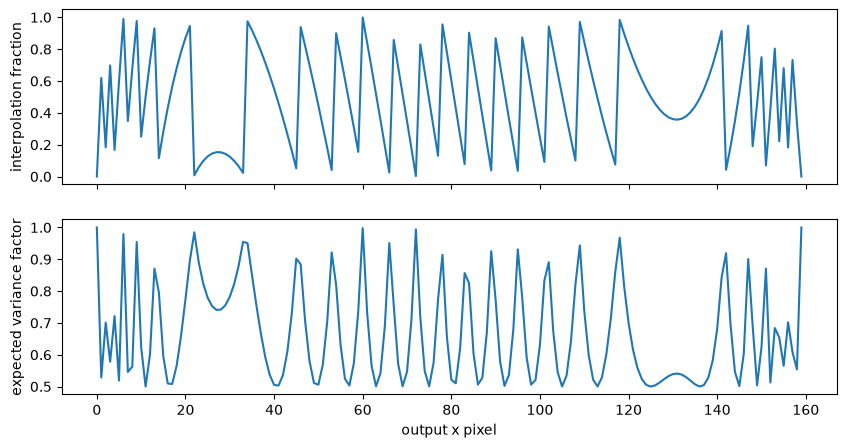

In [ ]:
n = 160
plan_old = make_resonant_downsample_plan(
    X=512,
    x0=joint_fit["x0"],
    A=joint_fit["A"],
    n_out=n,
)

theta_down = plan_old["theta_down"]
theta_x_out = plan_old["theta_x_out"]

dtheta = theta_down[1] - theta_down[0]

u = (theta_x_out - theta_down[0]) / dtheta

alpha = u - np.floor(u)

variance_factor = (1 - alpha) ** 2 + alpha**2

import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    2,
    1,
    figsize=(10, 5),
    sharex=True,
)

ax[0].plot(alpha)
ax[0].set_ylabel("interpolation fraction")

ax[1].plot(variance_factor)
ax[1].set_ylabel("expected variance factor")
ax[1].set_xlabel("output x pixel")

plt.show()

In [ ]:
plan = {}
movie = {}
for n in [256, 224, 192, 160]:

    plan[n] = make_resonant_downsample_plan_v2(
        X=512,
        x0=joint_fit["x0"],
        A=joint_fit["A"],
        n_out=n,
    )
    movie[n] = resonant_downsample_movie_v2(
        img_short,
        plan[n],
    )

In [ ]:
resampler = {}
movie_resampled = {}
for n in [256, 224, 192, 160]:
    resampler[n] = make_direct_theta_resampler(
        X=512,
        x0=joint_fit["x0"],
        A=joint_fit["A"],
        n_out=n,
    )

    movie_resampled[n] = direct_theta_downsample_movie(
        img_short,
        resampler[n],
    )

In [64]:
plan_old = make_resonant_downsample_plan(
    X=512,
    x0=joint_fit["x0"],
    A=joint_fit["A"],
    n_out=n,
)
movie_old = resonant_downsample_movie(
    img_short,
    plan_old,
)

In [ ]:
mean_old, std_old, noise_old = temporal_column_stats(movie_old)

mean_new, std_new, noise_new = temporal_column_stats(movie[160])

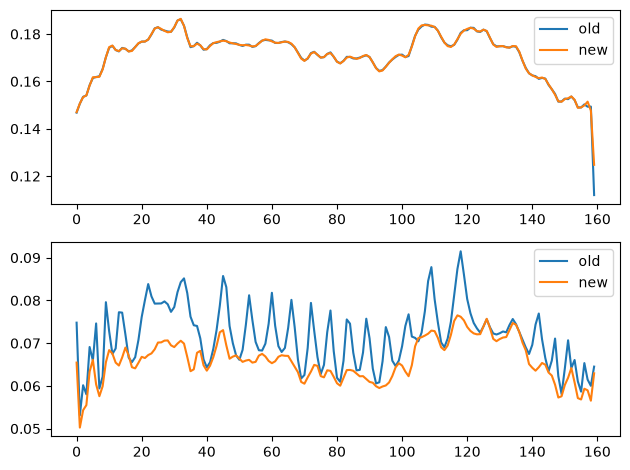

In [68]:
fig = plt.figure()
ax = fig.add_subplot(211)
ax.plot(mean_old, label="old")
ax.plot(mean_new, label="new")
ax.legend()

ax2 = fig.add_subplot(212)
ax2.plot(std_old, label="old")
ax2.plot(std_new, label="new")
ax2.legend()
plt.tight_layout()
plt.show()

In [ ]:
n = 160
resampler160 = make_direct_theta_resampler(
    X=512,
    x0=joint_fit["x0"],
    A=joint_fit["A"],
    n_out=n,
)

movie160_direct = direct_theta_downsample_movie(
    img_short,
    resampler160,
)

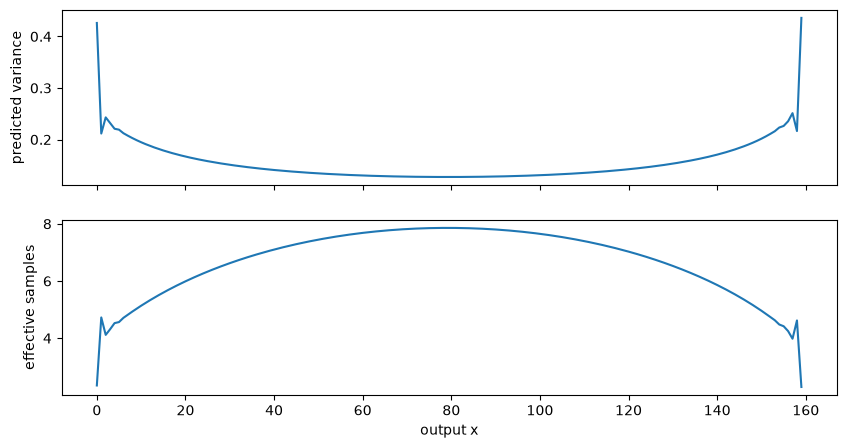

In [ ]:
W = resampler160["W"]

predicted_variance = np.sum(
    W**2,
    axis=1,
)

effective_samples = 1.0 / predicted_variance

fig, ax = plt.subplots(
    2,
    1,
    figsize=(10, 5),
    sharex=True,
)

ax[0].plot(predicted_variance)
ax[0].set_ylabel("predicted variance")

ax[1].plot(effective_samples)
ax[1].set_ylabel("effective samples")

ax[1].set_xlabel("output x")

plt.show()

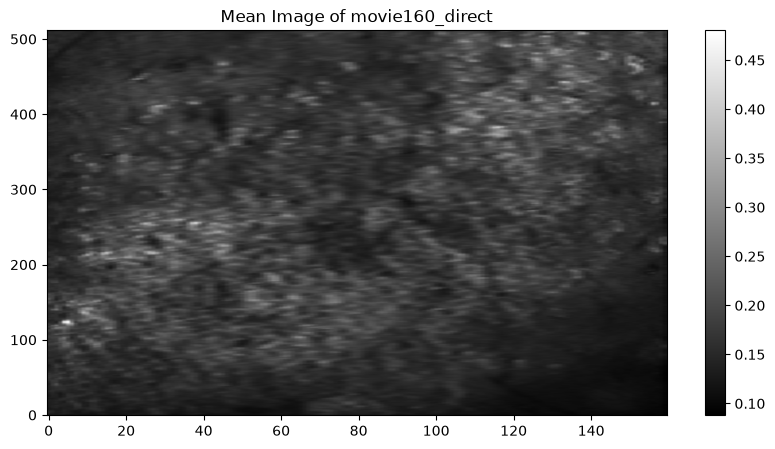

In [ ]:
img_mean = np.mean(movie160_direct, axis=0)
fig = plt.figure(figsize=(10, 5))
plt.imshow(img_mean, origin="lower", aspect="auto", cmap="gray")
plt.colorbar()
plt.title("Mean Image of movie160_direct")
plt.show()

In [ ]:
out_path = session_path / f"directly_sampled_movie_n={n}.tif"
save_data_as_tif(out_path, movie160_direct, True)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [78]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection import motion_correct
from turnover_dynamics.neuron_detection_caiman.neuron_detection.utils.parameters import (
    CaImAn as CaImAn_params,
)
from caiman.source_extraction import cnmf
import copy

params = copy.deepcopy(CaImAn_params)
params["show_movie"] = False  # whether to display movie while fitting
# params.update(kwargs)

n = 160
scale_factor = n / 512
# opts = cnmf.params.CNMFParams(params_dict=params)
# opts.set("motion", {
#     "max_shifts": (12,int(12*scale_factor)),
#     "strides": (96,int(96*scale_factor)),
#     "overlaps": (32,int(32*scale_factor))
# })
# opts.get_group("motion")

params["fr"] = 15.0
params["decay_time"] = 0.47
params["max_shifts"] = (12, int(12 * scale_factor))
params["strides"] = (96, int(96 * scale_factor))
params["overlaps"] = (32, int(32 * scale_factor))
print(params)

{'fr': 15.0, 'decay_time': 0.47, 'dxy': 0.9647998794000152, 'rf': 48, 'stride': 8, 'border_pix': 0, 'nb': 2, 'gSig': [10, 10], 'gSiz': (21, 21), 'min_SNR': 2.5, 'SNR_lowest': 1.0, 'rval_thr': 0.8, 'rval_lowest': -1, 'min_cnn_thr': 0.9, 'cnn_lowest': 0.1, 'use_cnn': True, 'motion_correct': False, 'epochs': 1, 'normalize': True, 'init_batch': 1000, 'init_method': 'cnmf', 'dist_shape_update': True, 'update_freq': 1000, 'use_dense': False, 'merge_thr': 0.65, 'max_shifts': (12, 3), 'strides': (96, 30), 'overlaps': (32, 10), 'max_deviation_rigid': 6, 'pw_rigid': True, 'show_movie': False, 'save_online_movie': False}


In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sun Aug 30 07:08:40 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:00<00:00,  8.92it/s]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


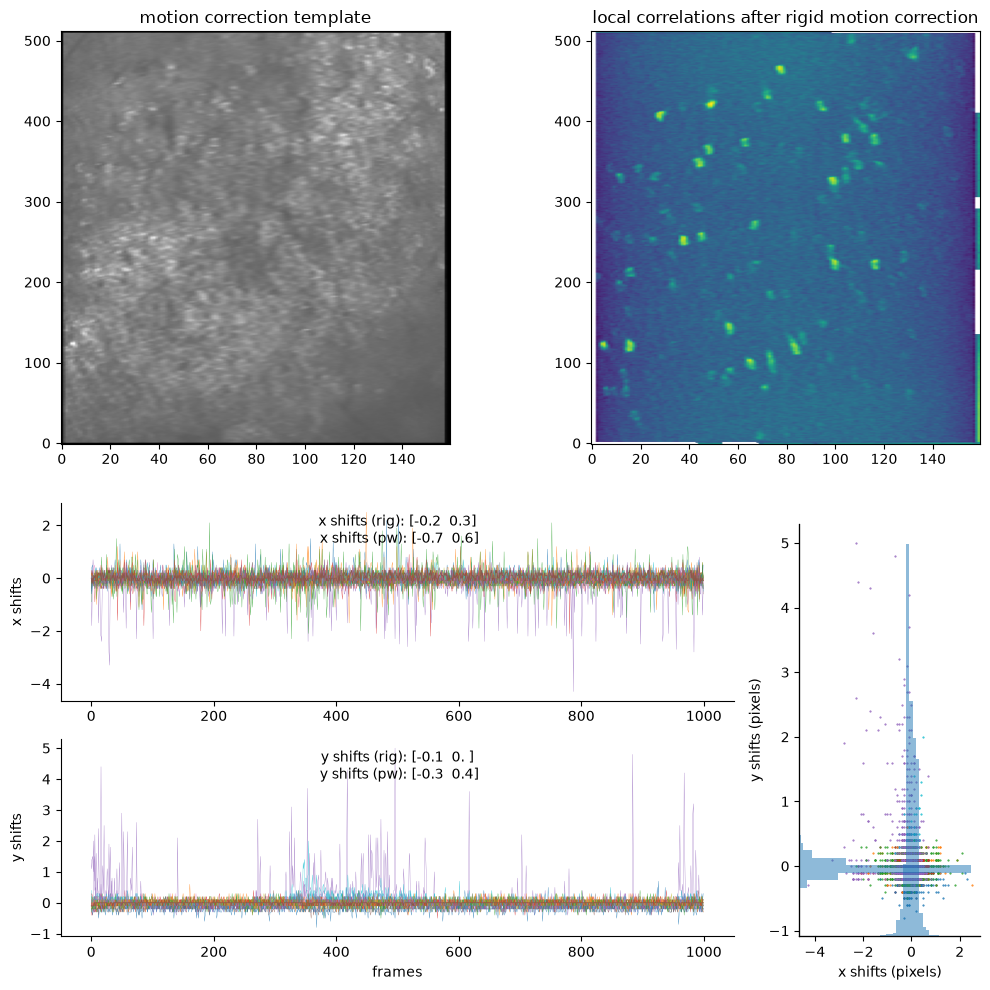

	Motion correction done @t = Sun Aug 30 07:09:14 2026, (time passed: 33.661757469177246)


'/home/wollex/caiman_data/temp/directly_sampled_movie_n=160_els__d1_512_d2_160_d3_1_order_F_frames_1000.mmap'

In [79]:
motion_correct(
    out_path,
    params=params,
    path_destination=session_path / "tmp",
    n_processes=1,
    plot=True,
)

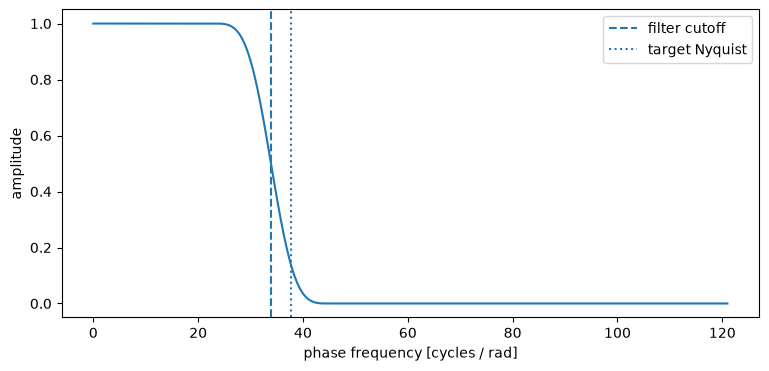

filter cutoff: 33.892597394530085
target Nyquist: 37.65844154947787


In [28]:
import matplotlib.pyplot as plt
from scipy.signal import freqz

w, response = freqz(
    plan["fir"],
    worN=2048,
    fs=plan["fs_dense"],
)

plt.figure(figsize=(9, 4))

plt.plot(w, np.abs(response))

plt.axvline(
    plan["cutoff"],
    ls="--",
    label="filter cutoff",
)

plt.axvline(
    plan["target_nyquist"],
    ls=":",
    label="target Nyquist",
)

plt.xlabel("phase frequency [cycles / rad]")
plt.ylabel("amplitude")
plt.legend()
plt.show()

print("filter cutoff:", plan["cutoff"])

print("target Nyquist:", plan["target_nyquist"])

## Analyze impact on correlation surface

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_correlation_surfaces import (
    analyze_movie_correlation_surfaces,
)

corr_surface = {}
for n in movie.keys():
    print(n)
    corr_surface[n], _ = analyze_movie_correlation_surfaces(
        movie_resampled[n],
        frame_lag=10,
        max_shift=5,
    )

256
224
192
160


In [89]:
original_results, _ = analyze_movie_correlation_surfaces(
    img_short,
    frame_lag=10,
    max_shift=5,
)

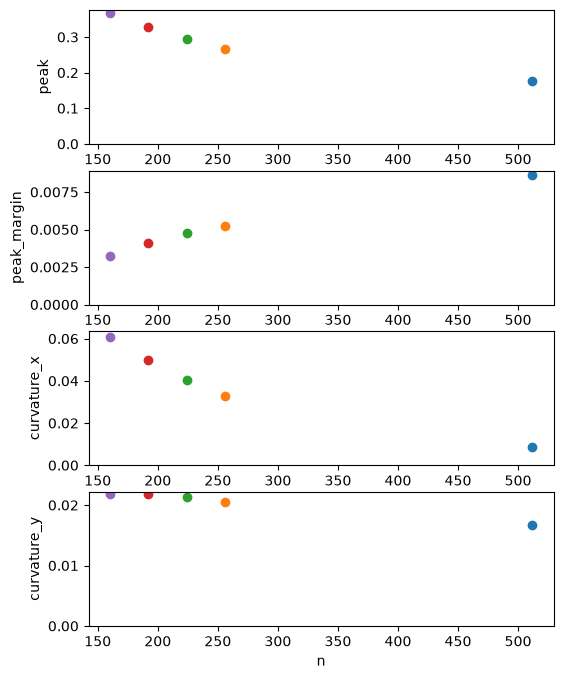

In [90]:
from matplotlib import pyplot as plt
import numpy as np


def get_median(stat, data):
    return np.median(np.array([r[stat] for r in data]))


def x_pixel_scale(n, original_n=512):
    return (original_n - 1) / (n - 1)


stats = ["peak", "peak_margin", "curvature_x", "curvature_y"]

fig, axes = plt.subplots(4, 1, figsize=(6, 8))

n = 512
for i, stat in enumerate(stats):
    median_value = get_median(stat, original_results)
    axes[i].scatter(n, median_value)

    axes[i].set_ylabel(stat)

axes[-1].set_xlabel("n")

for n in corr_surface.keys():
    for i, stat in enumerate(stats):
        median_value = get_median(stat, corr_surface[n])
        if i > 0 and i < 2:
            median_value /= x_pixel_scale(n) ** 2

        axes[i].scatter(n, median_value)
# for i, stat in enumerate(stats):
# axes[i].legend()

for ax in axes:
    ax.set_ylim(bottom=0)

plt.savefig(fig_path / "correlation_after_downsampling.png")

In [91]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection import motion_correct
from turnover_dynamics.neuron_detection_caiman.neuron_detection.utils.parameters import (
    CaImAn as CaImAn_params,
)
from caiman.source_extraction import cnmf
import copy

params = copy.deepcopy(CaImAn_params)
params["show_movie"] = False  # whether to display movie while fitting
# params.update(kwargs)

n = 256
scale_factor = n / 512
# opts = cnmf.params.CNMFParams(params_dict=params)
# opts.set("motion", {
#     "max_shifts": (12,int(12*scale_factor)),
#     "strides": (96,int(96*scale_factor)),
#     "overlaps": (32,int(32*scale_factor))
# })
# opts.get_group("motion")

params["fr"] = 15.0
params["decay_time"] = 0.47
params["max_shifts"] = (12, int(12 * scale_factor))
params["strides"] = (96, int(96 * scale_factor))
params["overlaps"] = (32, int(32 * scale_factor))
print(params)

{'fr': 15.0, 'decay_time': 0.47, 'dxy': 0.9647998794000152, 'rf': 48, 'stride': 8, 'border_pix': 0, 'nb': 2, 'gSig': [10, 10], 'gSiz': (21, 21), 'min_SNR': 2.5, 'SNR_lowest': 1.0, 'rval_thr': 0.8, 'rval_lowest': -1, 'min_cnn_thr': 0.9, 'cnn_lowest': 0.1, 'use_cnn': True, 'motion_correct': False, 'epochs': 1, 'normalize': True, 'init_batch': 1000, 'init_method': 'cnmf', 'dist_shape_update': True, 'update_freq': 1000, 'use_dense': False, 'merge_thr': 0.65, 'max_shifts': (12, 6), 'strides': (96, 48), 'overlaps': (32, 16), 'max_deviation_rigid': 6, 'pw_rigid': True, 'show_movie': False, 'save_online_movie': False}


In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_binning import (
    temporal_bin_movie,
)

binned_movie, frame_centers, bin_edges = temporal_bin_movie(
    movie[n], bin_size=2, method="mean"
)

In [50]:
out_path = session_path / f"downsampled_n_binned_movie_n={n}.tif"
save_data_as_tif(out_path, binned_movie, True)

  0%|          | 0/500 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sat Aug 29 21:34:43 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:00<00:00, 19.77it/s]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


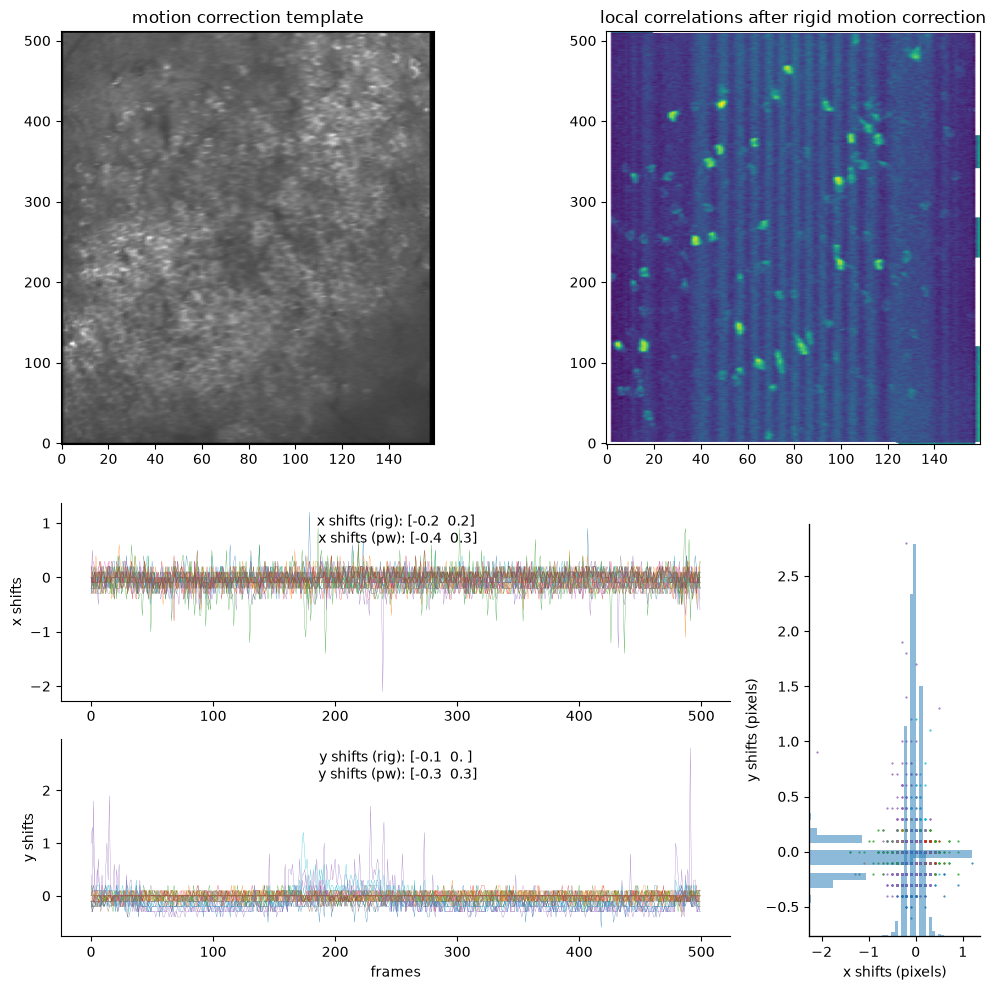

	Motion correction done @t = Sat Aug 29 21:34:58 2026, (time passed: 15.50421690940857)


'/home/wollex/caiman_data/temp/downsampled_n_binned_movie_n=160_els__d1_512_d2_160_d3_1_order_F_frames_500.mmap'

In [51]:
motion_correct(
    out_path,
    params=params,
    path_destination=session_path / "tmp",
    n_processes=1,
    plot=True,
)

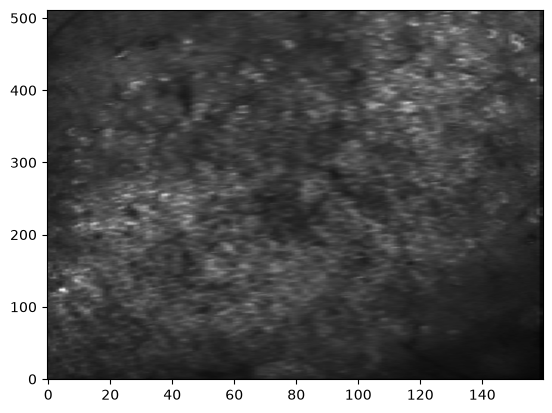

In [ ]:
img_mean = np.mean(movie[160], axis=0)
fig = plt.figure()
ax = fig.add_subplot(111)
ax.imshow(img_mean, origin="lower", aspect="auto", cmap="gray")
plt.show()

## looking into registration likelihood

In [ ]:
also, check previous data from PhD for the same effect! -> run detection on 3-4 different mice!

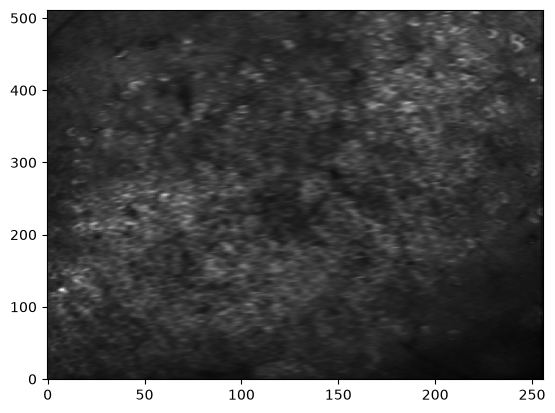

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_reg_likelihood import *

n = 256
template = np.mean(movie_resampled[n], axis=0)
fig = plt.figure()
ax = fig.add_subplot(111)
ax.imshow(template, origin="lower", aspect="auto", cmap="gray")
plt.show()
surfaces, shifts = template_correlation_surfaces(
    movie_resampled[n],
    template,
    max_shift=8,
)

In [93]:
# corr_temperature = 0.005
# corr_temperature = 0.01
# corr_temperature = 0.02

transition = make_motion_transition_kernel(
    radius=6,
    sigma_smooth=0.6,
    sigma_fast=2.5,
    fast_weight=0.05,
)

In [94]:
likelihood = correlation_to_likelihood(
    surfaces,
    corr_temperature=0.01,
)

transition = make_motion_transition_kernel(
    radius=6,
    sigma_smooth=0.6,
    sigma_fast=2.5,
    fast_weight=0.05,
)

posterior, alpha, beta = smooth_registration_likelihoods(
    likelihood,
    transition,
)

In [95]:
traj = trajectory_from_posterior(
    posterior,
    shifts,
)

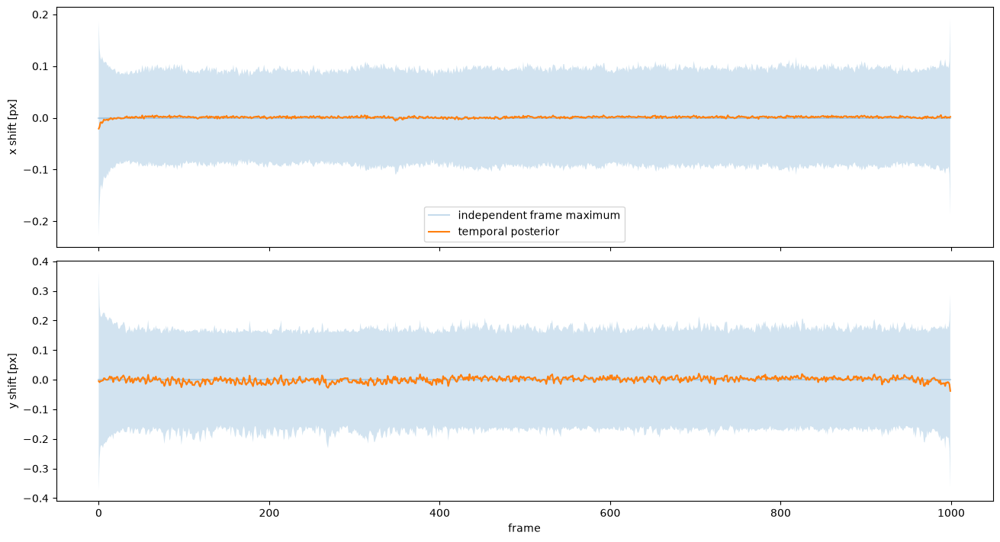

In [96]:
import matplotlib.pyplot as plt

dx_raw, dy_raw = independent_peak_trajectory(
    surfaces,
    shifts,
)


fig, ax = plt.subplots(
    2,
    1,
    figsize=(13, 7),
    sharex=True,
    constrained_layout=True,
)


ax[0].plot(
    dx_raw,
    alpha=0.25,
    label="independent frame maximum",
)

ax[0].plot(
    traj["dx_mean"],
    lw=1.5,
    label="temporal posterior",
)

ax[0].fill_between(
    np.arange(len(surfaces)),
    traj["dx_mean"] - traj["dx_std"],
    traj["dx_mean"] + traj["dx_std"],
    alpha=0.2,
)

ax[0].set_ylabel("x shift [px]")
ax[0].legend()


ax[1].plot(
    dy_raw,
    alpha=0.25,
)

ax[1].plot(
    traj["dy_mean"],
    lw=1.5,
)

ax[1].fill_between(
    np.arange(len(surfaces)),
    traj["dy_mean"] - traj["dy_std"],
    traj["dy_mean"] + traj["dy_std"],
    alpha=0.2,
)

ax[1].set_ylabel("y shift [px]")
ax[1].set_xlabel("frame")

plt.show()

In [97]:
score_path = correlation_along_trajectory(
    surfaces,
    shifts,
    traj["dx_mean"],
    traj["dy_mean"],
)

zero_idx = np.argmin(np.abs(shifts))

score_zero = surfaces[
    :,
    zero_idx,
    zero_idx,
]

print("mean correlation gain:", np.mean(score_path - score_zero))

print("median correlation gain:", np.median(score_path - score_zero))

mean correlation gain: 0.0
median correlation gain: 0.0


# attempt resampling + convolution fix

In [104]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_fix_convolution import *

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    damped_sinc_kernel,
)
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    fit_damped_sinc,
    phase_collapse_data,
    estimate_phase_kernel,
)

collapsed_294 = phase_collapse_data(
    results_m845ad["corr_even"],
    results_m845ad["corr_odd"],
    x0=joint_fit["x0"],
    A=joint_fit["A"],
)
theta_bin, K, K_std, count = estimate_phase_kernel(
    collapsed_294,
    n_bins=120,
)
damped_fit = fit_damped_sinc(collapsed_294)

theta_model = np.linspace(
    0,
    max(0.20, 6 * damped_fit["sigma"]),
    10000,
)

K_model = damped_sinc_kernel(
    theta_model,
    damped_fit["alpha"],
    damped_fit["tau"],
    damped_fit["sigma"],
)

freq_model = np.linspace(
    0,
    80,
    2000,
)
psd_model = np.empty_like(freq_model)

for i, f in enumerate(freq_model):
    psd_model[i] = 2 * np.trapezoid(
        K_model * np.cos(2 * np.pi * f * theta_model), theta_model
    )

psd_model /= psd_model[0]

H_model = np.sqrt(np.maximum(psd_model, 0))

In [109]:
resampler256_eq = make_equalized_resonant_resampler(
    X=512,
    x0=joint_fit["x0"],
    A=joint_fit["A"],
    n_out=256,
    freq_H=freq_model,
    H_old=H_model,
    regularization=0.15,
    max_gain=1.7,
    pass_fraction=0.85,
    stop_fraction=0.98,
)

safe target Nyquist: 36.02886171305964
passband: 30.624532456100695
stopband: 35.30828447879845


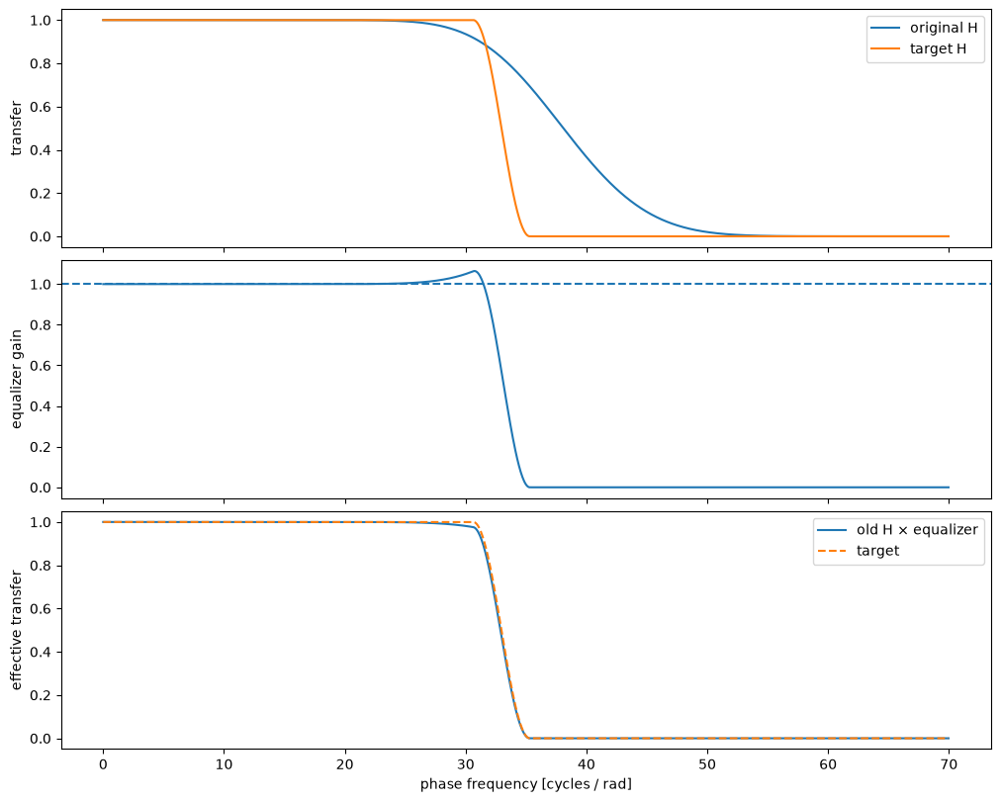

In [110]:
print(
    "safe target Nyquist:",
    resampler256_eq["f_nyquist_safe"],
)

print(
    "passband:",
    resampler256_eq["f_pass"],
)

print(
    "stopband:",
    resampler256_eq["f_stop"],
)

import matplotlib.pyplot as plt

r = resampler256_eq

mask = r["freq"] <= 70


fig, ax = plt.subplots(
    3,
    1,
    figsize=(10, 8),
    sharex=True,
    constrained_layout=True,
)


# Original vs desired
ax[0].plot(
    r["freq"][mask],
    r["H_old"][mask],
    label="original H",
)

ax[0].plot(
    r["freq"][mask],
    r["H_target"][mask],
    label="target H",
)

ax[0].set_ylabel("transfer")
ax[0].legend()


# Equalizer itself
ax[1].plot(
    r["freq"][mask],
    r["equalizer"][mask],
)

ax[1].axhline(
    1,
    ls="--",
)

ax[1].set_ylabel("equalizer gain")


# Effective result
ax[2].plot(
    r["freq"][mask],
    r["H_effective"][mask],
    label="old H × equalizer",
)

ax[2].plot(
    r["freq"][mask],
    r["H_target"][mask],
    ls="--",
    label="target",
)

ax[2].set_ylabel("effective transfer")
ax[2].set_xlabel("phase frequency [cycles / rad]")

ax[2].legend()

plt.show()

In [105]:
movie256_eq = apply_resampling_operator(
    img_short,
    resampler256_eq,
)

In [106]:
movie256_eq.shape

(1000, 512, 256)

In [ ]:
from to_be_sorted.tiff_align import TiffAlign

In [ ]:
movie_resampled[256].shape
save_path = session_path / "movie_resampled_256.tif"
save_data_as_tif(save_path, movie_resampled[256])

  0%|          | 0/1000 [00:00<?, ?it/s]

In [133]:
align_path = session_path / "aligned"
tA = TiffAlign(save_path, session_path / "aligned")

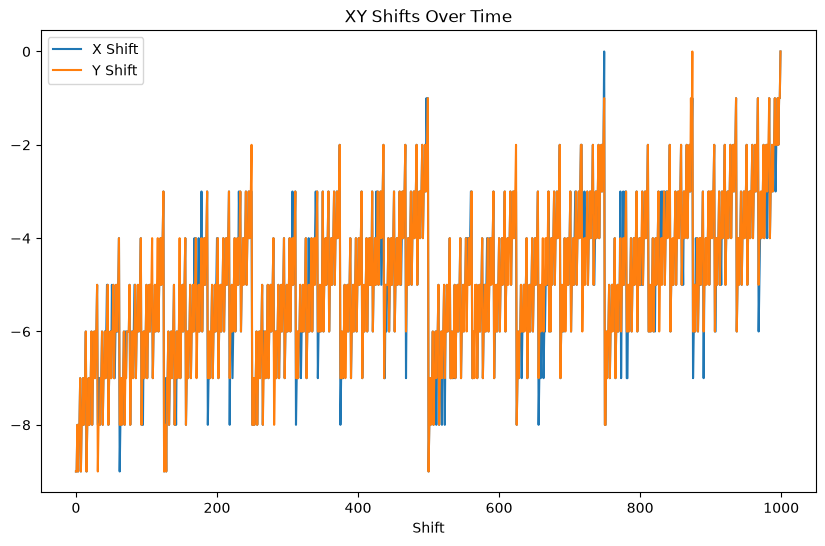

In [ ]:
tA.xy_shift

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111)
ax.plot(tA.xy_shift[:, 0], label="X Shift")
ax.plot(tA.xy_shift[:, 1], label="Y Shift")
ax.set_xlabel("Shift")
# ax.set_ylabel('Y Shift')
ax.set_title("XY Shifts Over Time")
ax.legend()
plt.show()

In [134]:
movie_resampled_aligned = tiff.imread(align_path / save_path.name)

In [124]:
mean_img_aligned = np.mean(movie_resampled_aligned, axis=0)
mean_img = np.mean(movie_resampled[256], axis=0)

In [138]:
movie_resampled_aligned.shape

(512, 256)

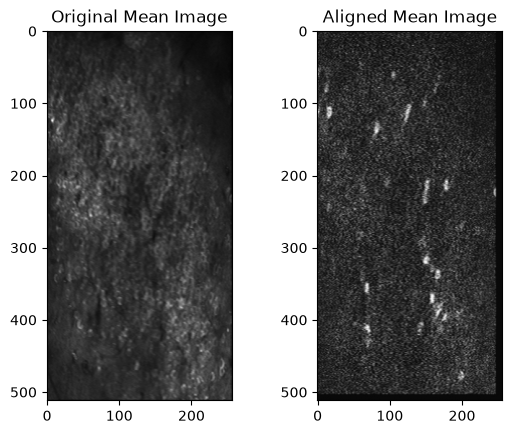

In [ ]:
fig, axes = plt.subplots(1, 2)
axes[0].imshow(mean_img, cmap="gray")
axes[0].set_title("Original Mean Image")
axes[1].imshow(movie_resampled_aligned, cmap="gray")
axes[1].set_title("Aligned Mean Image")
plt.show()

# resampling

In [6]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_pipeline import (
    make_resonant_phase_grids,
    movie_x_to_theta,
    movie_theta_to_x,
)

grids = make_resonant_phase_grids(
    X=512,
    x0=joint_fit["x0"],
    A=joint_fit["A"],
    n_theta=512,
)

In [7]:
m_theta = movie_x_to_theta(img_m845ad[:1000], grids)
m_roundtrip = movie_theta_to_x(m_theta, grids)

In [8]:
theta_span = grids["theta_uniform"][-1] - grids["theta_uniform"][0]

print(theta_span)

2.1110804571014503


In [ ]:
grids_256 = make_resonant_phase_grids(
    X=img_m845ad.shape[2],
    x0=joint_fit["x0"],
    A=joint_fit["A"],
    n_theta=256,
)

m_theta_256 = movie_x_to_theta(img_m845ad, grids_256)
m_mc = movie_theta_to_x(m_theta_256, grids_256)

In [10]:
d_img = img_m845ad - m_mc

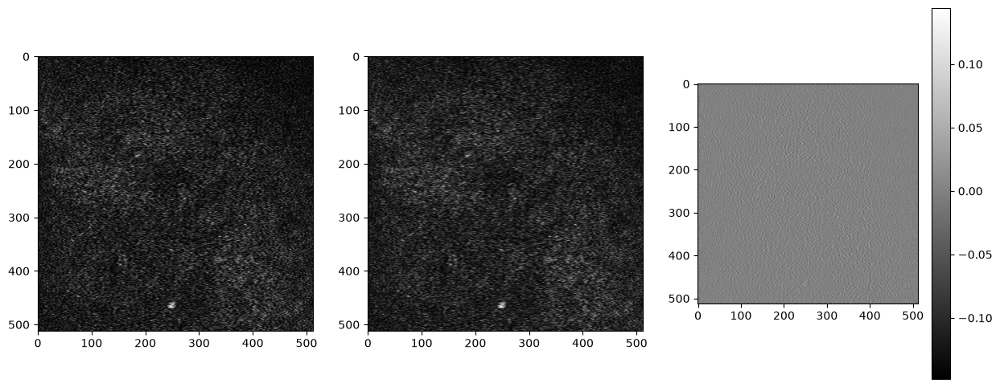

In [11]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

frame = 4400
im = axes[0].imshow(img_m845ad[frame, ...], cmap="gray")
# fig.colorbar(im)
im = axes[1].imshow(m_mc[frame, ...], cmap="gray")
# fig.colorbar(im)

im = axes[2].imshow(d_img[frame, ...], cmap="gray")
fig.colorbar(im)

plt.show()

In [12]:
out_path = session_path / "scanning_correction_output.tif"

In [ ]:
save_data_as_tif(out_path, m_mc[:1000, ...], normalize=True)

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Fri Aug 28 22:22:47 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:00<00:00,  2.57it/s]


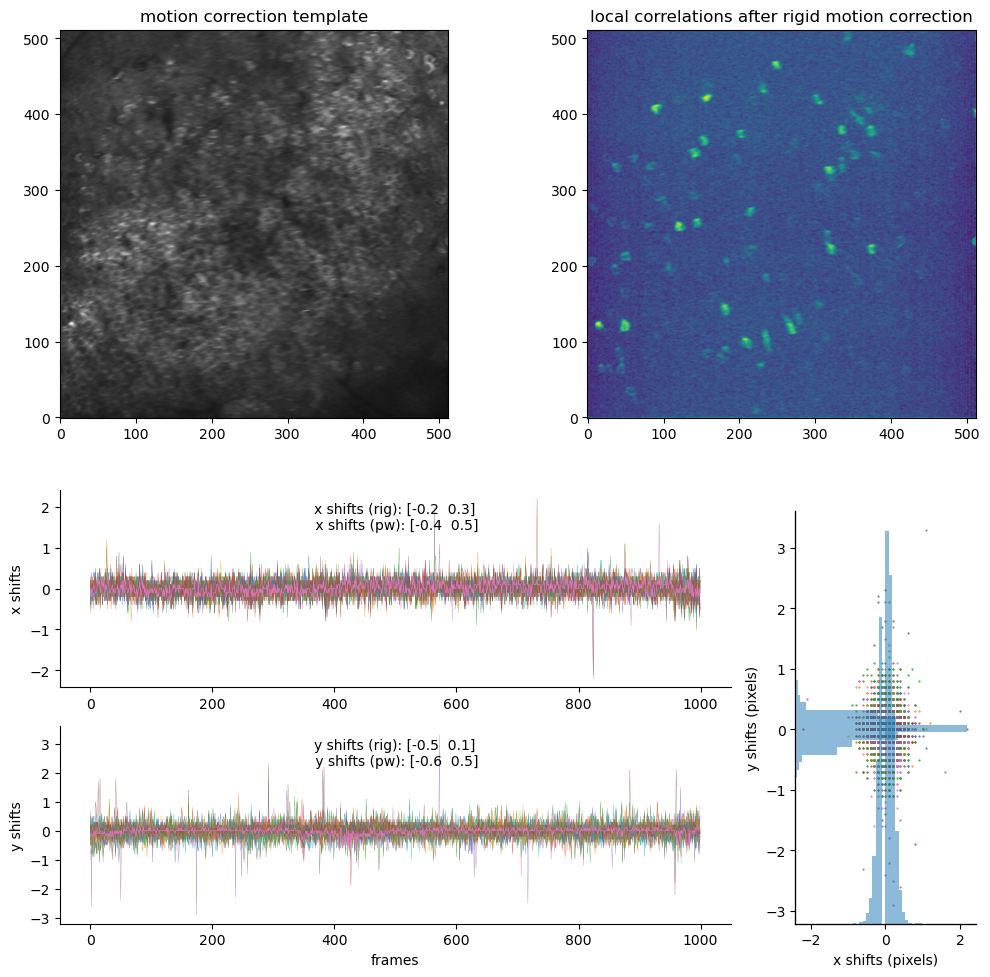

	Motion correction done @t = Fri Aug 28 22:24:40 2026, (time passed: 112.35533666610718)


'/home/wollex/caiman_data/temp/scanning_correction_output_els__d1_512_d2_512_d3_1_order_F_frames_1000.mmap'

In [ ]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection import motion_correct
from turnover_dynamics.neuron_detection_caiman.neuron_detection.utils.parameters import (
    CaImAn as CaImAn_params,
)
import copy

params = copy.deepcopy(CaImAn_params)
params["show_movie"] = False  # whether to display movie while fitting
# params.update(kwargs)
motion_correct(
    out_path,
    params=params,
    path_destination=session_path / "tmp",
    n_processes=1,
    plot=True,
)

In [14]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_phase_domain_spectrum import (
    covariance_cosine_spectrum,
)
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    fit_damped_sinc,
    phase_collapse_data,
    estimate_phase_kernel,
)

collapsed_294 = phase_collapse_data(
    results_m845ad["corr_even"],
    results_m845ad["corr_odd"],
    x0=joint_fit["x0"],
    A=joint_fit["A"],
)
theta_bin, K, K_std, count = estimate_phase_kernel(
    collapsed_294,
    n_bins=120,
)
damped_fit = fit_damped_sinc(collapsed_294)

freq, psd_emp, H_emp = covariance_cosine_spectrum(
    theta_bin,
    K,
    K0=damped_fit["alpha"],
    theta_max=0.08,
    f_max=80,
)

In [15]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_pipeline import (
    movie_x_to_theta,
    movie_theta_to_x,
    whiten_theta_movie,
)

beta = 0.4
regularization = 0.15
max_gain = 1.7
cutoff = 45

# 1. uniform phase representation
m_theta = movie_x_to_theta(img_m845ad, grids_256)

# 2. partial whitening
m_theta_w, W, freq_fft = whiten_theta_movie(
    m_theta,
    grids_256["theta_uniform"],
    freq,
    psd_emp,
    beta=0.4,
    regularization=0.15,
    max_gain=1.7,
    cutoff=45,
)

# 3. back into normal physical x coordinates
m_mc_whitened = movie_theta_to_x(m_theta_w, grids_256)

In [16]:
out_path = session_path / "scanning_correction_and_whitening.tif"
save_data_as_tif(out_path, m_mc_whitened[:1000, ...], normalize=True)

  0%|          | 0/1000 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sat Aug 29 05:47:23 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:00<00:00,  3.13it/s]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


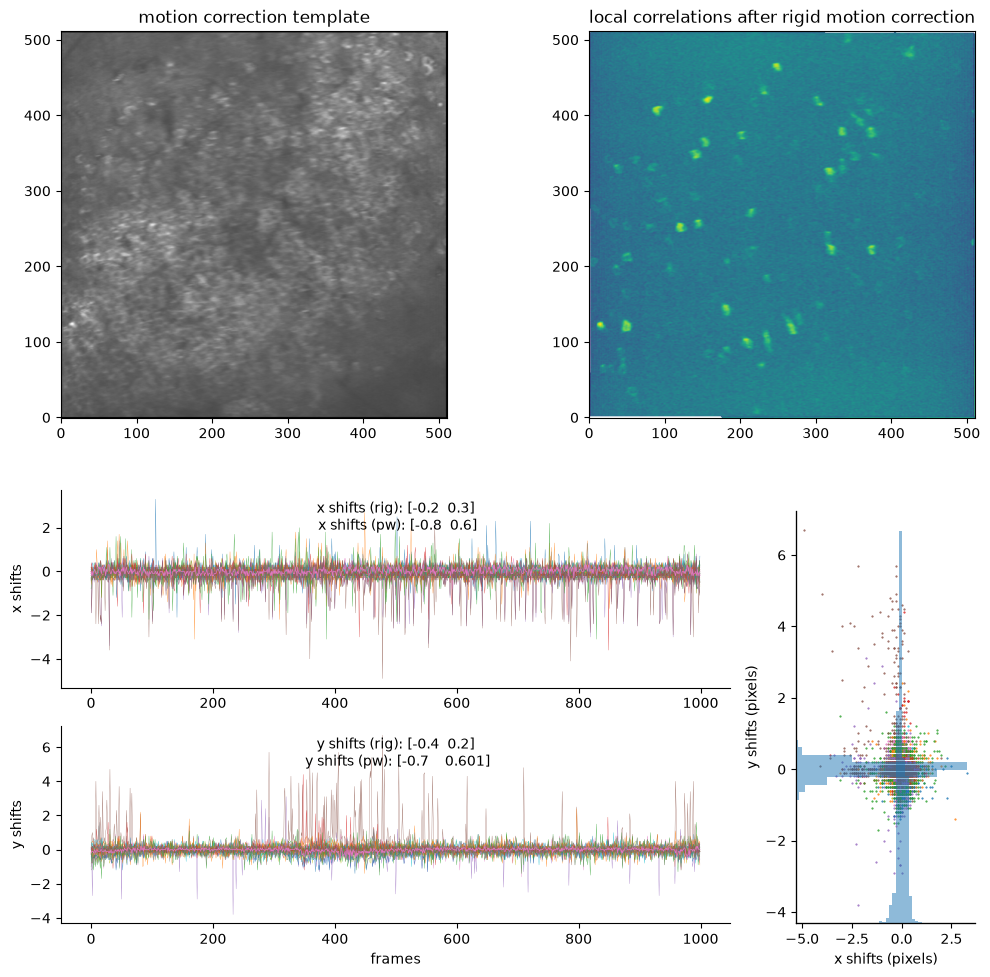

	Motion correction done @t = Sat Aug 29 05:49:19 2026, (time passed: 115.87344932556152)


'/home/wollex/caiman_data/temp/scanning_correction_and_whitening_els__d1_512_d2_512_d3_1_order_F_frames_1000.mmap'

In [17]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection import motion_correct
from turnover_dynamics.neuron_detection_caiman.neuron_detection.utils.parameters import (
    CaImAn as CaImAn_params,
)
import copy

params = copy.deepcopy(CaImAn_params)
params["show_movie"] = False  # whether to display movie while fitting
# params.update(kwargs)
motion_correct(
    out_path,
    params=params,
    path_destination=session_path / "tmp",
    n_processes=1,
    plot=True,
)

  0%|          | 0/2247 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sat Aug 29 06:41:46 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:01<00:00,  1.13s/it]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


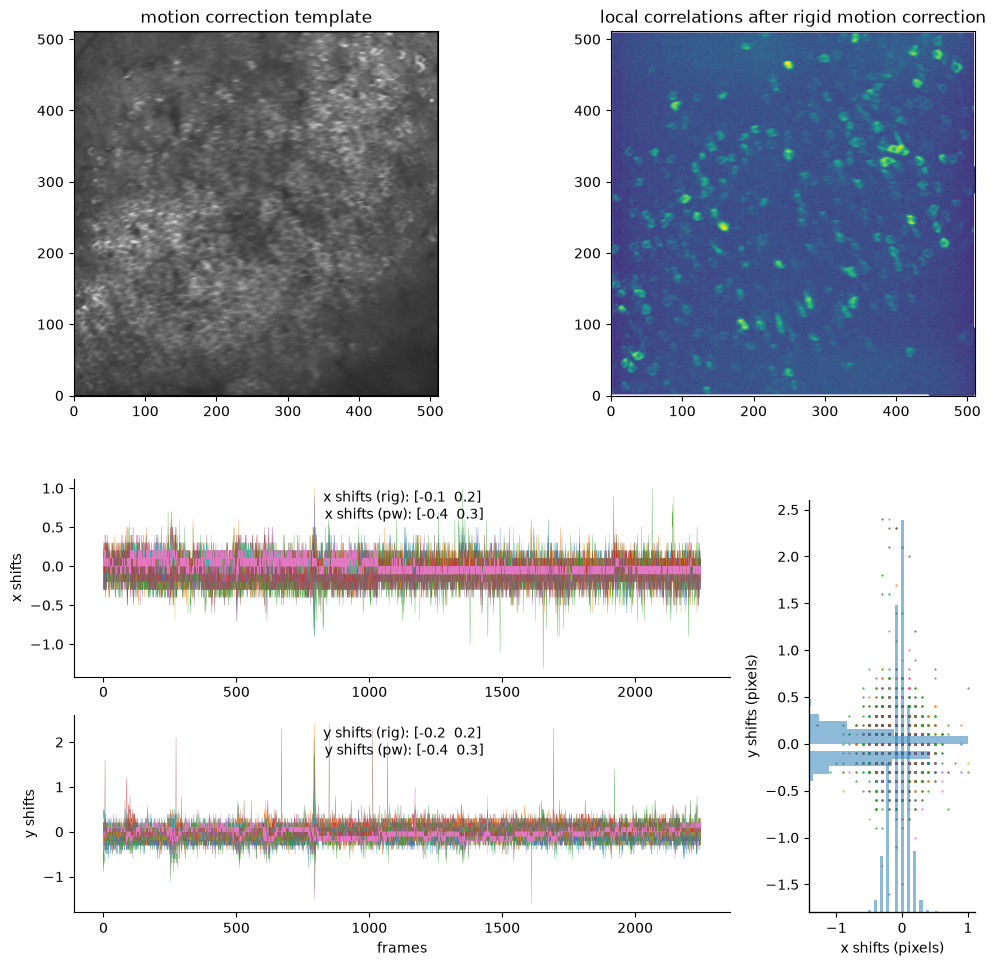

	Motion correction done @t = Sat Aug 29 06:46:25 2026, (time passed: 279.2775025367737)


  0%|          | 0/2247 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sat Aug 29 06:47:12 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:04<00:00,  4.80s/it]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


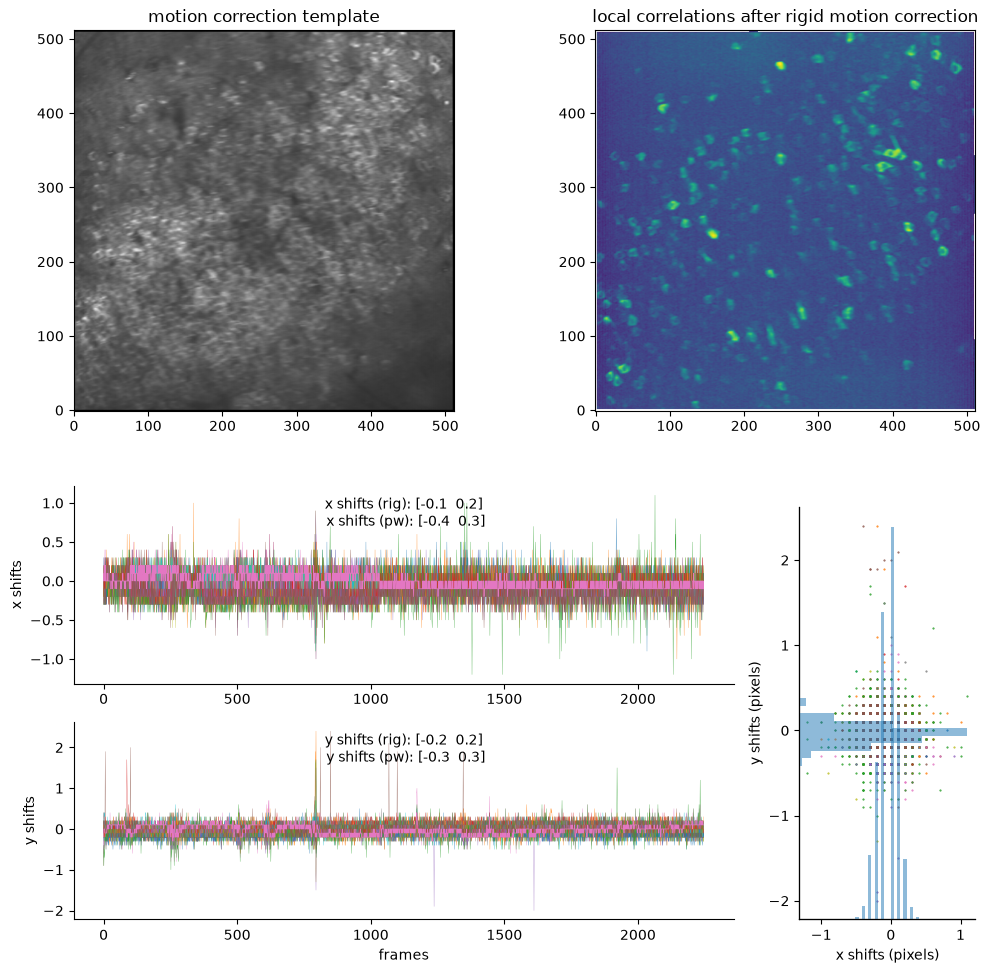

	Motion correction done @t = Sat Aug 29 06:52:03 2026, (time passed: 290.7228422164917)


  0%|          | 0/1123 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sat Aug 29 06:52:15 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:00<00:00,  2.62it/s]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


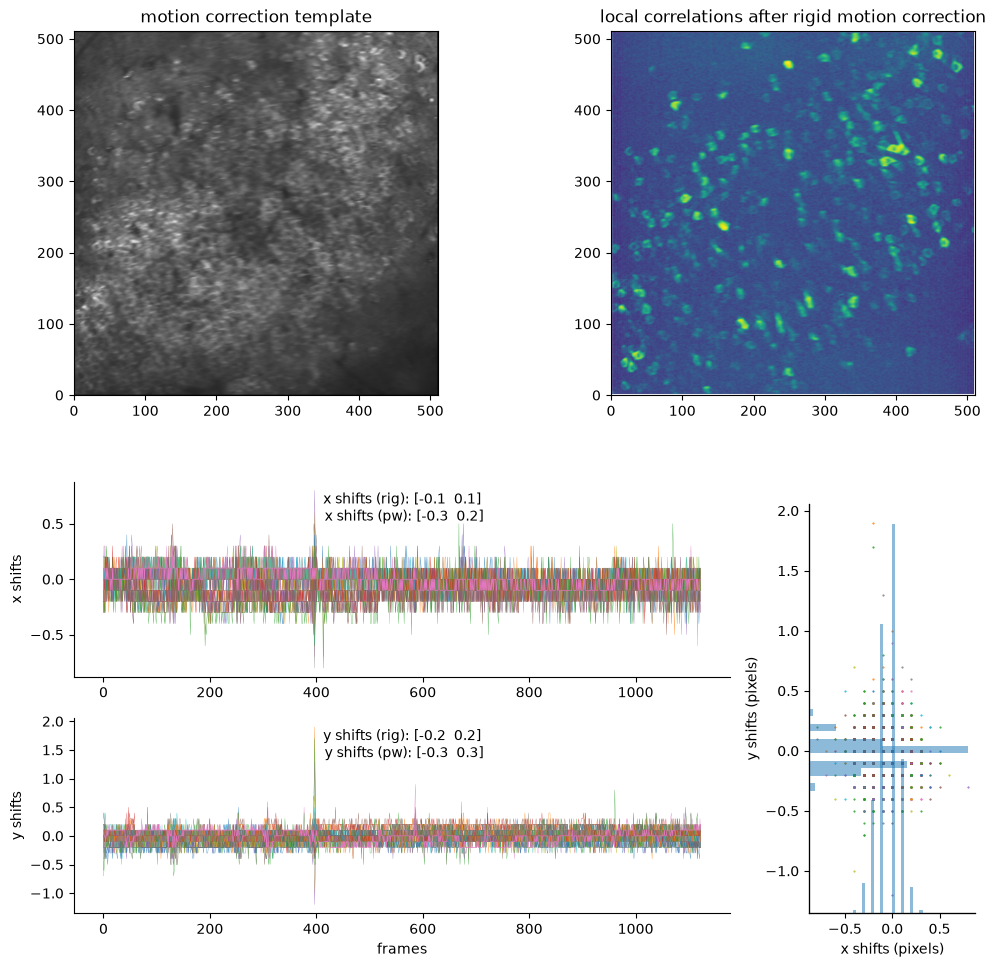

	Motion correction done @t = Sat Aug 29 06:54:31 2026, (time passed: 136.12030386924744)


  0%|          | 0/1123 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sat Aug 29 06:55:18 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:03<00:00,  3.43s/it]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


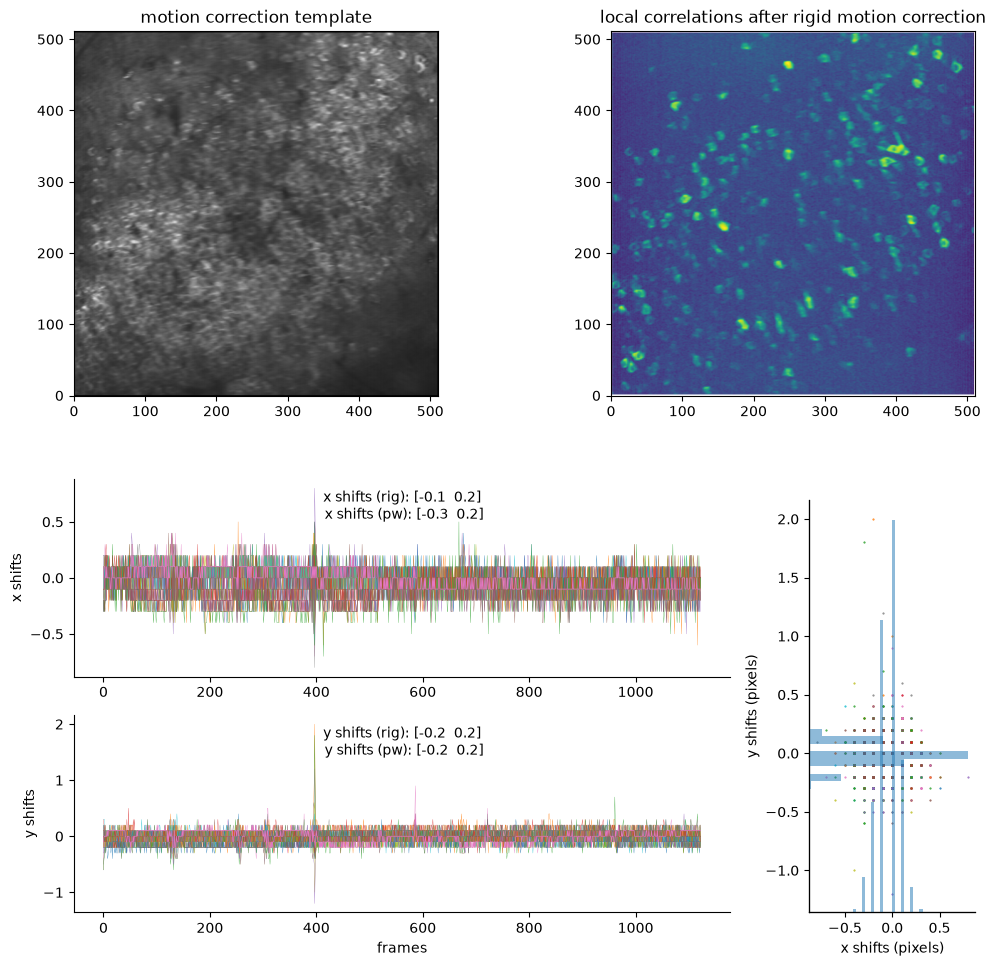

	Motion correction done @t = Sat Aug 29 06:57:37 2026, (time passed: 139.51902437210083)


  0%|          | 0/561 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sat Aug 29 06:57:44 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:00<00:00,  5.28it/s]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


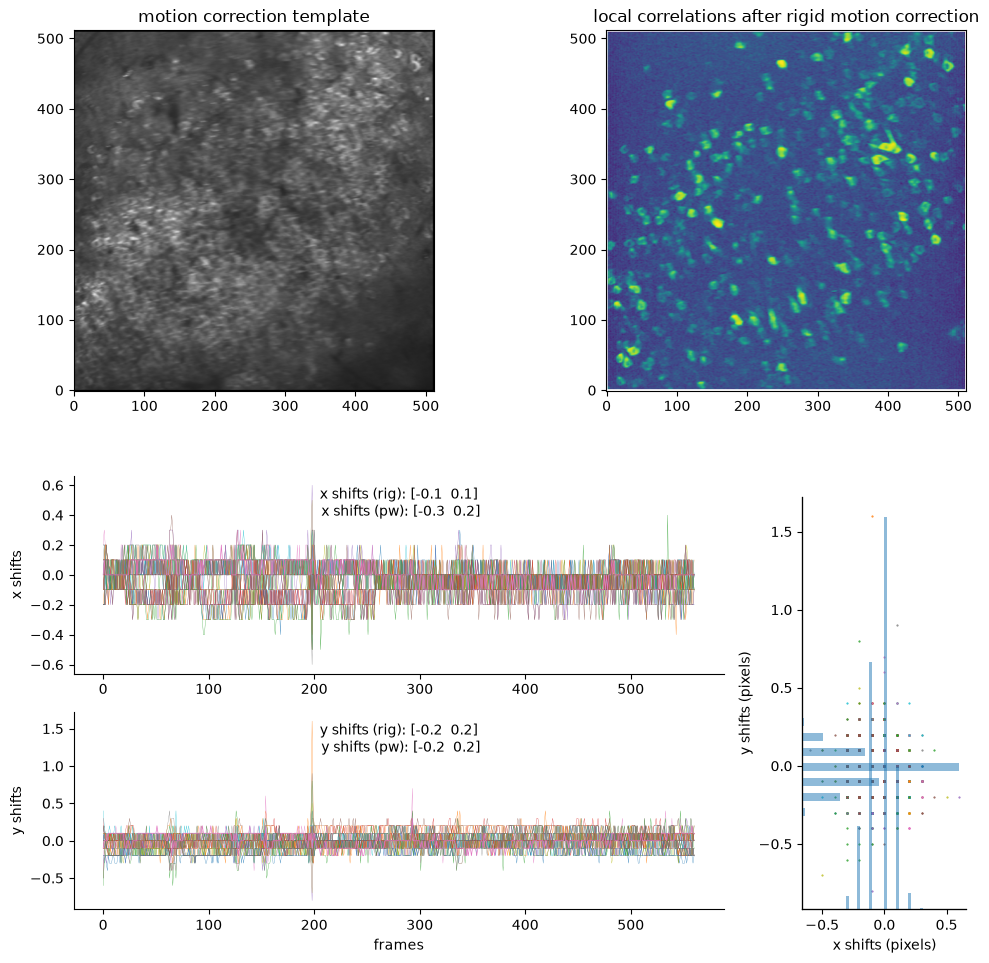

	Motion correction done @t = Sat Aug 29 06:58:42 2026, (time passed: 58.32590842247009)


  0%|          | 0/561 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sat Aug 29 06:59:52 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:00<00:00,  1.01it/s]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


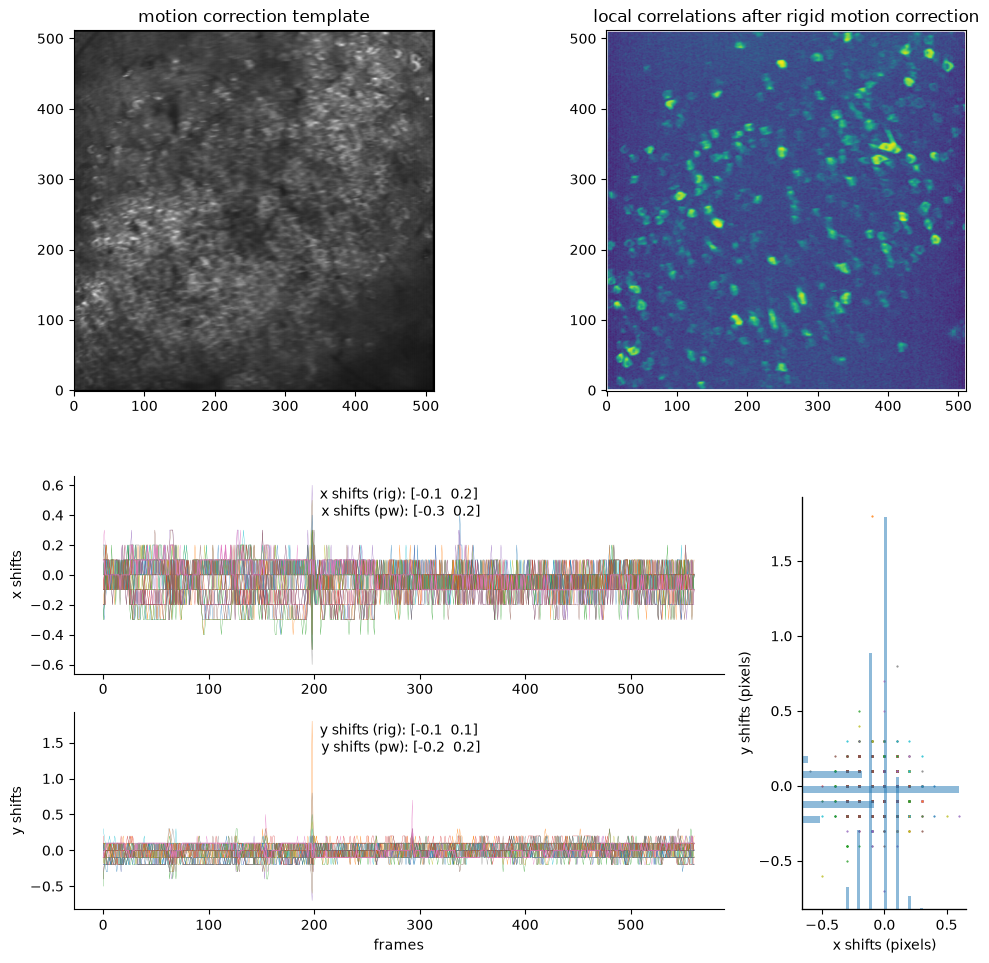

	Motion correction done @t = Sat Aug 29 07:00:54 2026, (time passed: 62.03764820098877)


In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_binning import (
    temporal_bin_movie,
)

img_binned = {}

for bin_size in [4, 8, 16]:
    for method in ["mean", "median"]:
        binned_movie, frame_centers, bin_edges = temporal_bin_movie(
            m_mc, bin_size=bin_size, method=method
        )
        img_binned[(bin_size, method)] = (binned_movie, frame_centers, bin_edges)

        out_path = session_path / f"resampled_{method}_binned_{bin_size}_img.tif"
        save_data_as_tif(out_path, img_binned[(bin_size, method)][0], True)

        motion_correct(
            out_path,
            params=params,
            path_destination=session_path / "tmp",
            n_processes=1,
            plot=True,
        )

In [ ]:
# img_binned[2][0]
# print(img_binned[16][1][:5])
for bin_size in [2, 4, 8, 16]:
    out_path = session_path / f"binned_{bin_size}_img.tif"
    save_data_as_tif(out_path, img_binned[bin_size][0], True)

  0%|          | 0/4494 [00:00<?, ?it/s]

  0%|          | 0/2247 [00:00<?, ?it/s]

  0%|          | 0/1123 [00:00<?, ?it/s]

  0%|          | 0/561 [00:00<?, ?it/s]

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Sat Aug 29 06:18:46 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:01<00:00,  1.26s/it]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


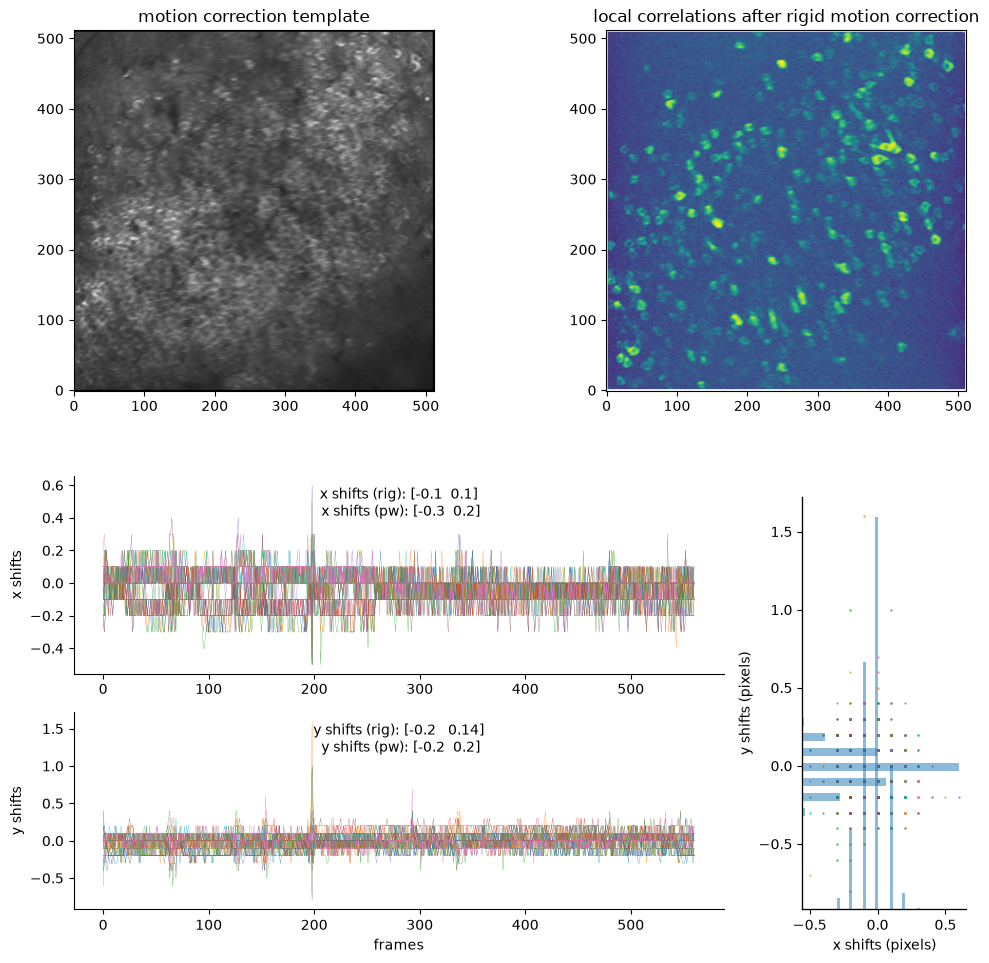

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Motion correction done @t = Sat Aug 29 06:19:49 2026, (time passed: 62.77734398841858)
	Now running motion correction @t = Sat Aug 29 06:19:49 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:02<00:00,  2.06s/it]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


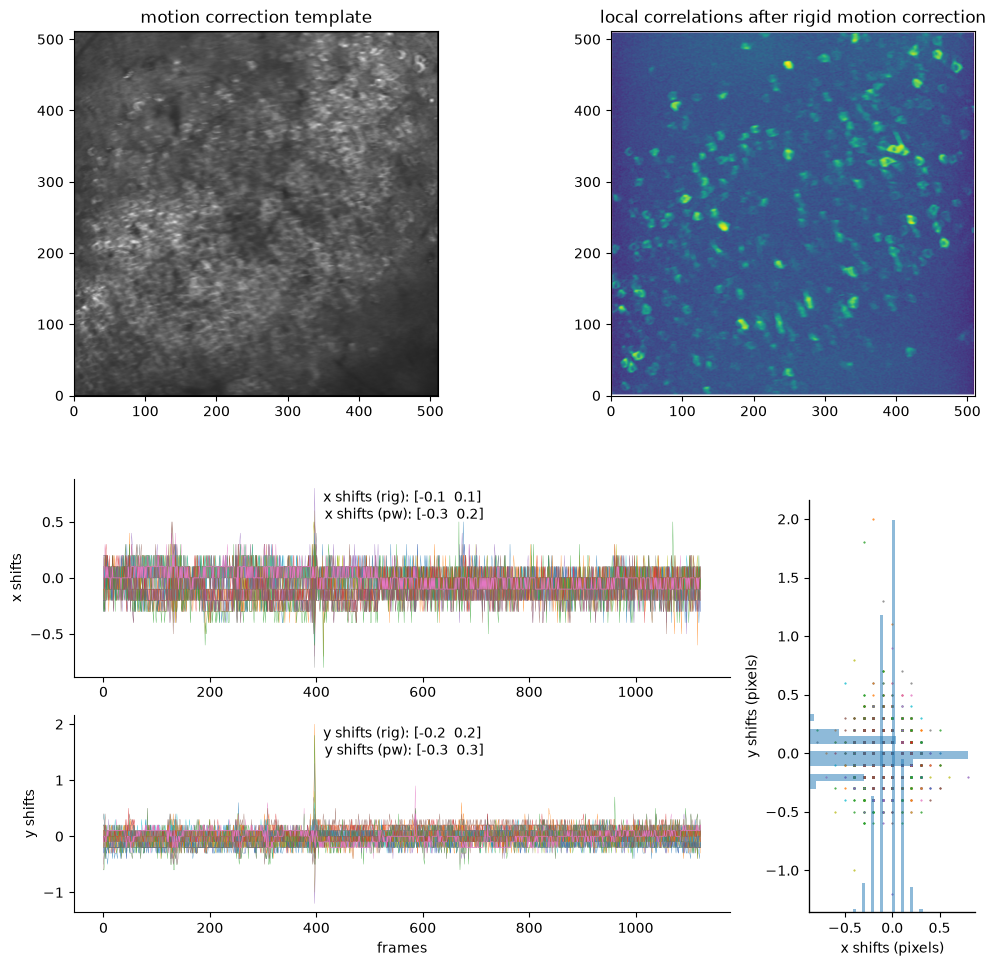

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Motion correction done @t = Sat Aug 29 06:22:06 2026, (time passed: 137.3547158241272)
	Now running motion correction @t = Sat Aug 29 06:22:07 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:03<00:00,  3.44s/it]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


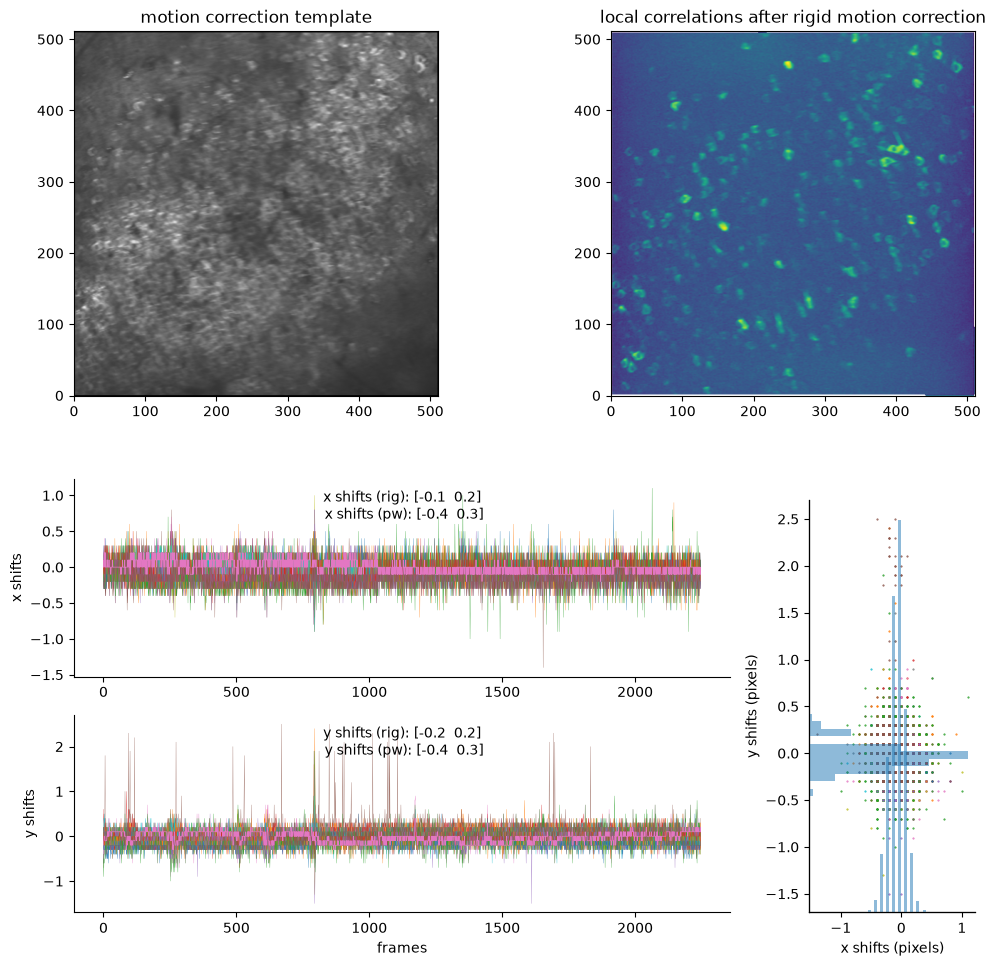

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Motion correction done @t = Sat Aug 29 06:26:50 2026, (time passed: 283.80007219314575)
	Now running motion correction @t = Sat Aug 29 06:26:50 2026
Now running the actual motion correction...


100%|██████████| 1/1 [00:07<00:00,  7.93s/it]
/home/wollex/miniforge3/envs/neuron_detection/lib/python3.12/site-packages/caiman/summary_images.py:210: RuntimeWarning: invalid value encountered in divide
  w_mov = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


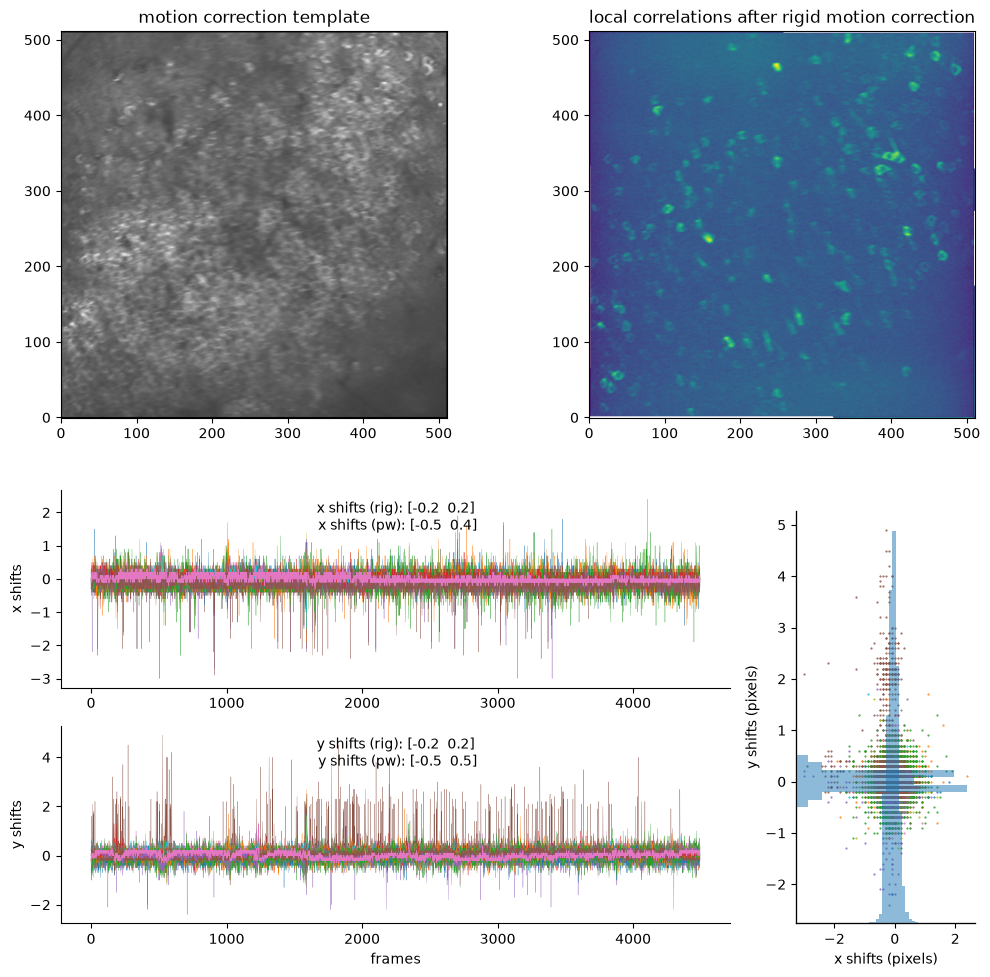

	Motion correction done @t = Sat Aug 29 06:37:08 2026, (time passed: 617.7110962867737)


In [ ]:
for bin_size in [16, 8, 4]:
    out_path = session_path / f"resampled_binned_{bin_size}_img.tif"
    motion_correct(
        out_path,
        params=params,
        path_destination=session_path / "tmp",
        n_processes=1,
        plot=True,
    )

In [ ]:
movie_bin64, centers64, _ = temporal_bin_movie(
    img_m845ad,
    bin_size=64,
    method="mean",
)

In [29]:
display_videos([movie_bin64])

dims=(140, 512, 512)
dims=(140, 512, 512)


error: OpenCV(5.0.0) /home/conda/feedstock_root/build_artifacts/libopencv_1786395764748/work/modules/highgui/src/window_QT.cpp:258: error: (-27:Null pointer) NULL guiReceiver (please create a window) in function 'cvGetPropVisible_QT'


In [35]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_correlation_surfaces import (
    analyze_movie_correlation_surfaces,
)

corr_results, shifts = analyze_movie_correlation_surfaces(
    img_binned[(4, "mean")][0],
    frame_lag=1,
    max_shift=5,
)

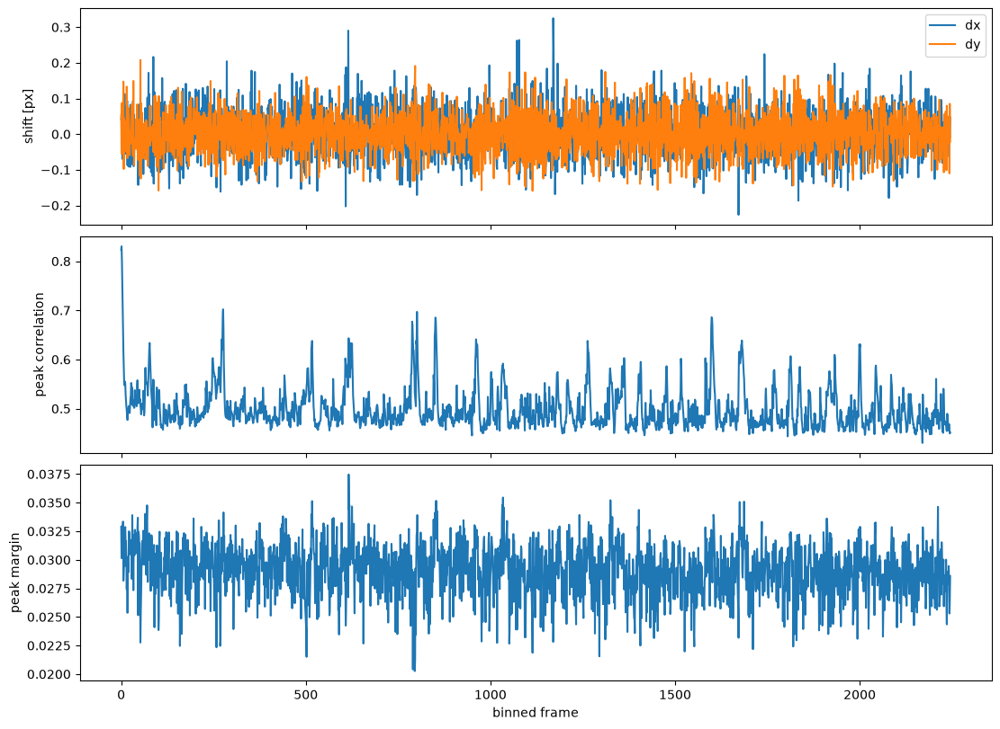

In [36]:
dx = np.array([r["dx"] for r in corr_results])

dy = np.array([r["dy"] for r in corr_results])

peak = np.array([r["peak"] for r in corr_results])

margin = np.array([r["peak_margin"] for r in corr_results])

fig, ax = plt.subplots(
    3,
    1,
    figsize=(11, 8),
    sharex=True,
    constrained_layout=True,
)

ax[0].plot(dx, label="dx")
ax[0].plot(dy, label="dy")
ax[0].set_ylabel("shift [px]")
ax[0].legend()

ax[1].plot(peak)
ax[1].set_ylabel("peak correlation")

ax[2].plot(margin)
ax[2].set_ylabel("peak margin")
ax[2].set_xlabel("binned frame")

plt.show()

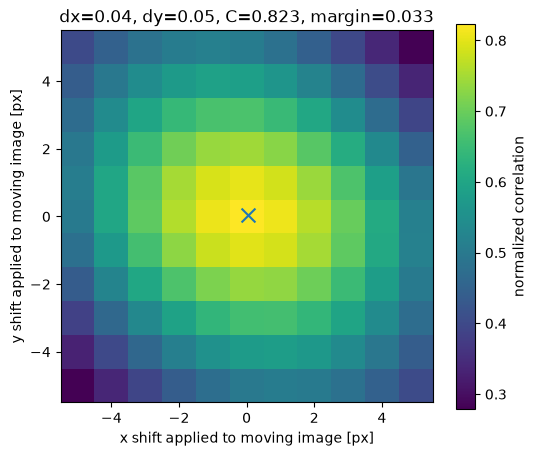

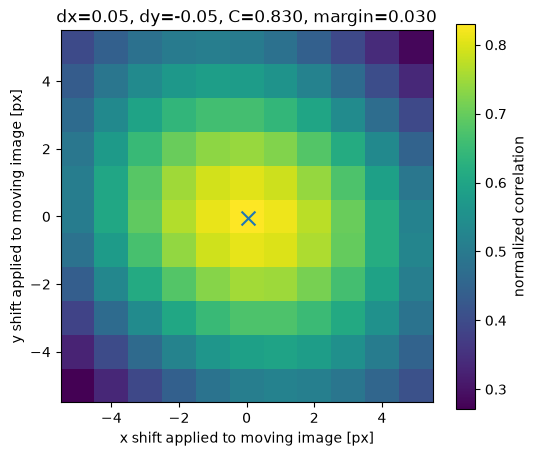

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_correlation_surfaces import (
    plot_correlation_surface,
)

good = (peak > np.percentile(peak, 75)) & (margin > np.percentile(margin, 75))

good_idx = np.where(good)[0]
bad_idx = np.where(~good)[0]

plot_correlation_surface(
    corr_results[good_idx[0]]["surface"],
    shifts,
    corr_results[good_idx[0]],
)

plot_correlation_surface(
    corr_results[bad_idx[0]]["surface"],
    shifts,
    corr_results[bad_idx[0]],
)

In [38]:
img_short = img_m845ad[:1000, ...]

# Deconvolve

In [39]:
regularization = 0.15
max_gain = 1.7
cutoff = 50.0

In [ ]:
grids_dec = make_resonant_phase_grids(
    X=img_short.shape[2],
    x0=joint_fit["x0"],
    A=joint_fit["A"],
    n_theta=512,
)

In [42]:
movie_theta = movie_x_to_theta(
    img_short,
    grids_dec,
)

In [ ]:
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.correction_deconvolution import (
    deconvolve_theta_movie,
)
from turnover_dynamics.neuron_detection_caiman.scanning_artifacts.diagnostics_forward_model import (
    damped_sinc_kernel,
)

theta_model = np.linspace(
    0,
    max(0.20, 6 * damped_fit["sigma"]),
    10000,
)

K_model = damped_sinc_kernel(
    theta_model,
    damped_fit["alpha"],
    damped_fit["tau"],
    damped_fit["sigma"],
)

freq_model = np.linspace(
    0,
    80,
    2000,
)
psd_model = np.empty_like(freq_model)

for i, f in enumerate(freq_model):
    psd_model[i] = 2 * np.trapezoid(
        K_model * np.cos(2 * np.pi * f * theta_model), theta_model
    )

psd_model /= psd_model[0]

H_model = np.sqrt(np.maximum(psd_model, 0))

In [54]:
import matplotlib.pyplot as plt


def plot_deconvolution_results(freq_dec, G_dec, H_dec, title):
    fig, ax = plt.subplots(
        3,
        1,
        figsize=(9, 8),
        sharex=True,
        constrained_layout=True,
    )

    ax[0].plot(freq_dec, H_dec, label="H_dec")
    ax[0].plot(freq_dec, H_dec * G_dec, label="H_dec * G_dec")

    ax[0].set_ylabel("estimated H")

    ax[1].plot(freq_dec, G_dec, label="G_dec")

    ax[1].axhline(
        1,
        ls="--",
    )

    ax[1].set_ylabel("inverse gain G")

    ax[2].plot(freq_dec, H_dec * G_dec, label="net H × G")

    ax[2].axhline(
        1,
        ls="--",
    )

    ax[2].set_ylabel("net H × G")
    ax[0].legend()
    ax[1].legend()
    ax[2].legend()

    ax[2].set_xlabel("phase frequency [cycles / rad]")
    plt.suptitle(title)
    # plt.show()
    plt.savefig(fig_path / f"{title}.png")

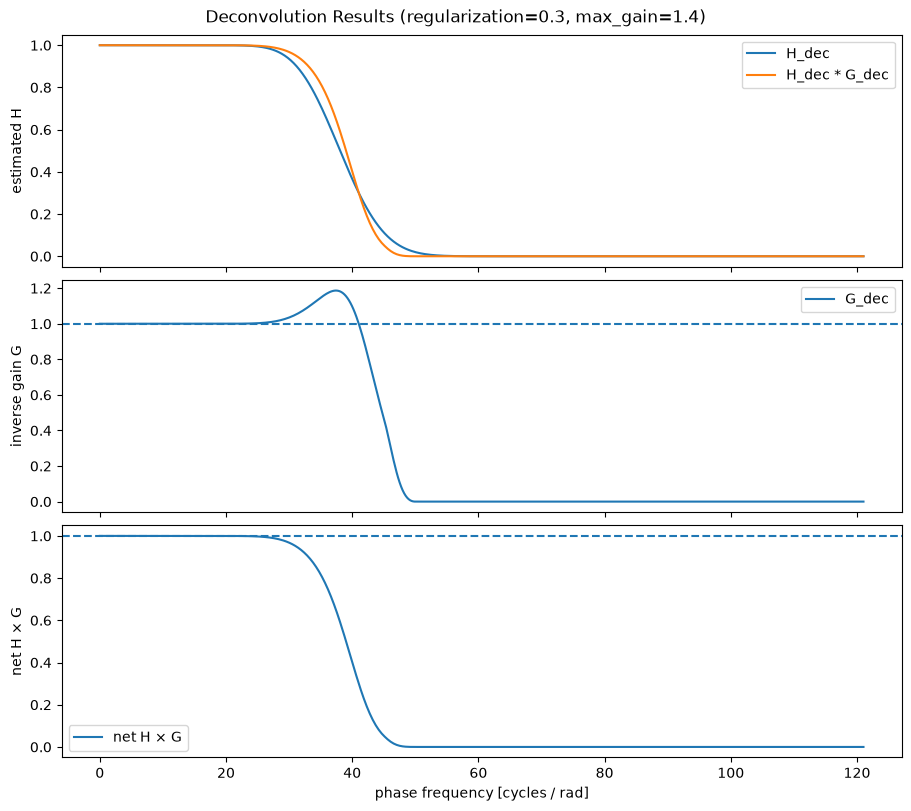

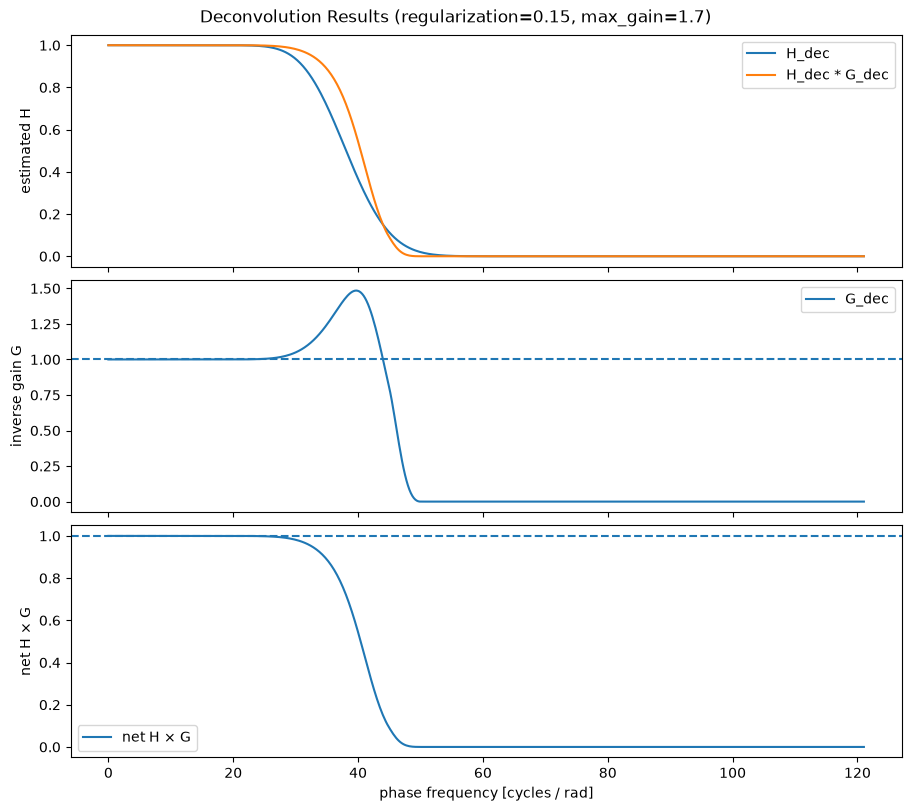

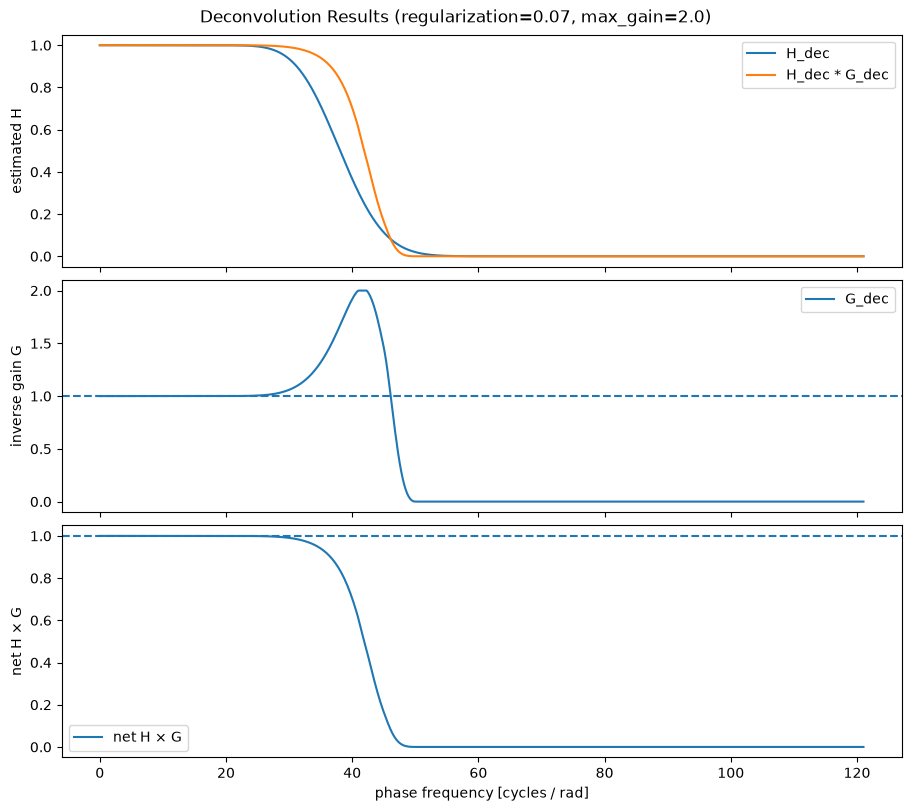

In [ ]:
configs = [
    dict(
        regularization=0.30,
        max_gain=1.4,
    ),
    dict(
        regularization=0.15,
        max_gain=1.7,
    ),
    dict(
        regularization=0.07,
        max_gain=2.0,
    ),
]

for conf in configs:
    movie_theta_dec, freq_dec, G_dec, H_dec = deconvolve_theta_movie(
        movie_theta,
        grids_dec["theta_uniform"],
        # I recommend starting with these:
        freq_model,
        H_model,
        regularization=conf["regularization"],
        max_gain=conf["max_gain"],
        cutoff=50.0,
        cutoff_width=5.0,
    )

    movie_dec = movie_theta_to_x(
        movie_theta_dec,
        grids_dec,
    )

    plot_deconvolution_results(
        freq_dec,
        G_dec,
        H_dec,
        title=f"Deconvolution Results (regularization={conf['regularization']}, max_gain={conf['max_gain']})",
    )

In [56]:
original_results, _ = analyze_movie_correlation_surfaces(
    img_short,
    frame_lag=10,
    max_shift=5,
)

dec_results, _ = analyze_movie_correlation_surfaces(
    movie_dec,
    frame_lag=10,
    max_shift=5,
)

In [ ]:
# original_results


def plot_stats(ax, stat: str):
    # fig = plt.figure(figsize=(9, 6))
    peak_margin = np.array([r[stat] for r in original_results])
    ax.hist(peak_margin, bins=20, alpha=0.5, label="Original")
    ax.axvline(
        np.median(peak_margin), color="tab:green", linestyle="dashed", linewidth=1
    )

    peak_margin = np.array([r[stat] for r in dec_results])
    ax.hist(peak_margin, bins=20, alpha=0.5, label="Dec")
    ax.axvline(np.median(peak_margin), color="tab:red", linestyle="dashed", linewidth=1)

    ax.set_xlabel(stat)
    ax.set_ylabel("Frequency")
    ax.set_title(f"Distribution of {stat} in Original and Dec Results")
    ax.legend()
    # plt.show()

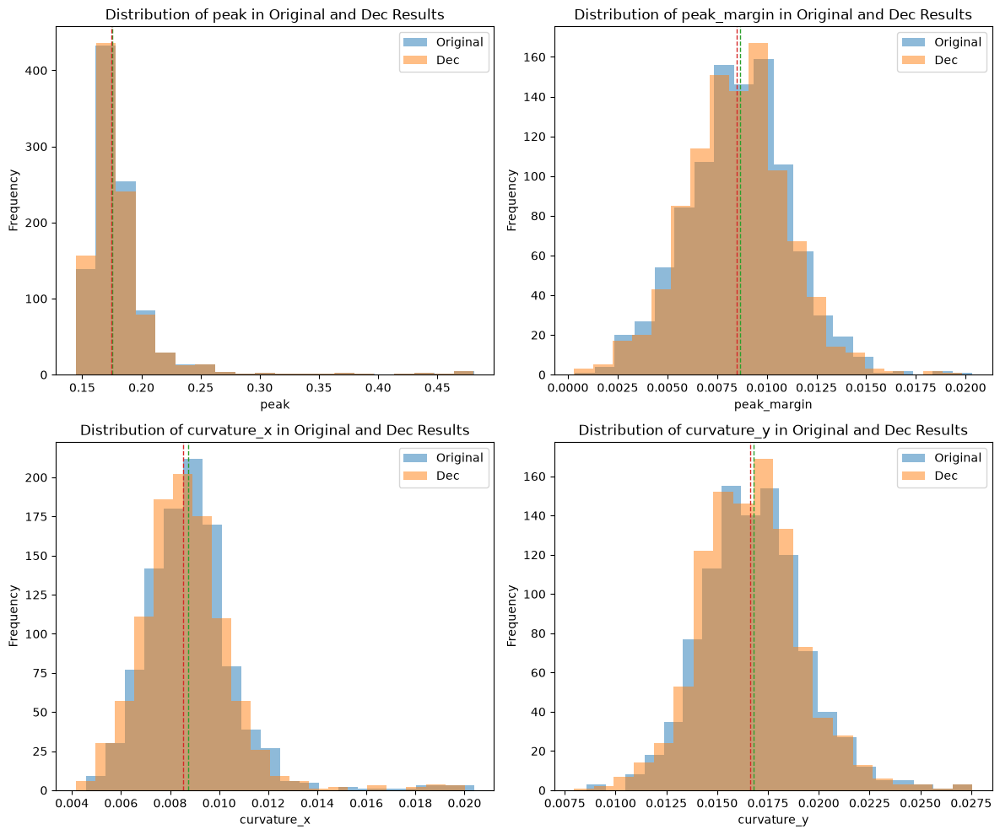

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
plot_stats(axes[0, 0], "peak")
plot_stats(axes[0, 1], "peak_margin")
plot_stats(axes[1, 0], "curvature_x")
plot_stats(axes[1, 1], "curvature_y")
plt.tight_layout()
# plt.show()
plt.savefig(fig_path / "scanning_correction_stats.png")

In [72]:
results_dec = diagnose_resonant_scan(movie_dec)

In [ ]:
info_dec = effective_x_information(
    results_dec["corr_even"],
    results_dec["corr_odd"],
    max_lag=15,
)

print("original center:", np.nanmedian(info845["redundancy"][230:280]))

print("deconvolved center:", np.nanmedian(info_dec["redundancy"][230:280]))

In [ ]:
binned_dec, frame_centers, bin_edges = temporal_bin_movie(
    m_mc, bin_size=2, method="mean"
)

out_path = session_path / f"deconvolved_binned_img.tif"
save_data_as_tif(out_path, binned_dec, True)

motion_correct(
    out_path,
    params=params,
    path_destination=session_path / "tmp",
    n_processes=1,
    plot=True,
)

In [71]:
display_videos([img_short, movie_dec], display_mode="common", percentiles=[20, 99.9])

dims=(1000, 512, 512)
dims=(1000, 512, 512)


TypeError: 'tuple' object is not callable

TypeError: 'tuple' object is not callable

TypeError: 'tuple' object is not callable

TypeError: 'tuple' object is not callable

...

TypeError: 'tuple' object is not callable

TypeError: 'tuple' object is not callable

TypeError: 'tuple' object is not callable

TypeError: 'tuple' object is not callable

error: OpenCV(5.0.0) /home/conda/feedstock_root/build_artifacts/libopencv_1786395764748/work/modules/highgui/src/window_QT.cpp:258: error: (-27:Null pointer) NULL guiReceiver (please create a window) in function 'cvGetPropVisible_QT'
